# CTA Bus Reliability Analysis: annotated notebook

Every code cell below now has a short explanation above it. Each explanation covers **what the cell does**, **how it works**, and **what it found** (where there is a result). Cells are numbered in their original order (Cell 1 is the first code cell).

## Roadmap

| Part | Cells | Purpose |
|---|---|---|
| A. Data access and inspection | 1-10 | Download CTA StopWatch data, inspect one pattern, discover its structure |
| B. Choosing routes and loading | 11-17 | Build a catalog of patterns, pick busy routes, load April 2026, choose a reference stop |
| C. Headways, cleaning, route profile (Investigation 1) | 18-26 | Compute headways, diagnose artifacts, flag bunching and big gaps, summarize routes |
| D. Route differences (Investigation 2) | 27-31 | Coverage screening, normalization, Welch ANOVA, Kruskal-Wallis, Holm post-hoc |
| E. Time of day and weekday vs weekend (Investigations 3-4) | 32-36 | Regression, interaction, Friedman, weekday/weekend tests |
| F. Speed as a congestion proxy and weather (Investigation 5) | 37-41 | Speed diagnostics, hour-normalization, speed regressions, rain and temperature |
| G. Final three-month dataset | 42-43 | Memory-safe loader for April to June 2026, and the key results re-run |
| H. Unpredictability and late-arrival model (Investigations 6-7) | 44-45 | Bootstrap CIs per route, logistic regression for big gaps |
| I. Final route comparison and heatmap | 46-47 | Investigation 2 re-run on the final data, big-gap heatmap |

## Important notes before you read on

- **"Delay" is replaced by headway.** The data has no scheduled times, so reliability is measured from *headways* (minutes between consecutive buses at a stop), normalized by each pattern's usual headway. "Late" becomes **big gap** (headway more than 2x the usual).
- **Arrival times are estimates**, interpolated from 5-minute bus location pings.
- **Some cells are superseded** by later, better versions. They are kept so the story of the analysis is traceable, and each is marked *(superseded)*.
- **Run order matters.** Later cells depend on variables from earlier ones (for example `mid` from Cell 17 is used in Cell 42, and `wx` and `spd` are redefined in Cell 43). If you re-run only a late cell after a kernel restart, it will fail. Use *Restart and Run All* when in doubt.
- **Known quirk:** Cell 24 uses a variable named `stats` for a list, which shadows `scipy.stats`. Cell 28 re-imports `scipy.stats`, so this is harmless when running top to bottom, but re-running Cell 24 alone after Cell 28 would break later cells. Rename it (for example to `boot_stats`) if you want to clean it up.


### Cell 1: imports
Loads three libraries: `requests` (to download files over HTTP), `pandas` (tables), and `Path` from `pathlib` (file paths that work on any operating system).

In [1]:
import requests
import pandas as pd
from pathlib import Path

### Cell 2: configuration
- `BASE` is the root URL of the Mansueto Institute StopWatch data bucket.
- `DATA_DIR` is the local folder `data/raw` where downloads are saved.
- `mkdir(parents=True, exist_ok=True)` creates the folder if it is missing and does nothing if it already exists.

In [2]:
BASE = "https://d2v7z51jmtm0iq.cloudfront.net/cta-stop-watch"
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

### Cell 3: download helper
Defines `download(url, dest)`. If the file already exists locally it skips the download (so re-running is cheap). Otherwise it fetches the URL, raises an error on a bad HTTP status (`raise_for_status`), writes the bytes to disk, and prints the size. It returns the local path, so other cells can chain it into `pd.read_*`.

In [3]:
def download(url, dest):
    dest = Path(dest)
    if dest.exists():
        print(f"already have {dest}")
        return dest
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    dest.write_bytes(r.content)
    print(f"downloaded {dest} ({dest.stat().st_size/1e6:.1f} MB)")
    return dest

## Part A. Data access and inspection
### Cell 4: route-to-pattern lookup
Downloads `rt_to_pid.csv` and loads it. A CTA **route** (`rt`, for example `22`) has several **patterns** (`pid`), which are specific direction/variant paths. The lookup maps one to the other.

**Result:** 940 rows and 2 columns (`rt` as text, `pid` as integer). `rt` is text because some routes have letters, like `49B`.

In [4]:
lookup_path = download(f"{BASE}/rt_to_pid.csv", DATA_DIR / "rt_to_pid.csv")
lookup = pd.read_csv(lookup_path)
print(lookup.shape)
print(lookup.dtypes)
lookup.head(10)

downloaded data/raw/rt_to_pid.csv (0.0 MB)
(940, 2)
rt     object
pid     int64
dtype: object


,rt,pid
0,52,14128
1,55,5425
2,70,1500
3,97,4369
4,53A,845
5,80,3082
6,52A,7458
7,49,1180
8,47,6125
9,49B,4107


### Cell 5: pick one pattern and download it
Looks for columns whose name contains "pid", takes the first pattern ID in the lookup, and downloads that pattern's processed parquet file (one file per pattern, holding estimated stop-level arrival times).

**Lesson learned:** the first row was an arbitrary choice (Route 52, a sparse limited-service variant). It was fine for inspecting the file's structure, but it is a poor basis for analysis, which is why Part B builds a proper catalog.

In [5]:
pid_cols = [col for col in lookup.columns if "pid" in col.lower()]
print("candidate pattern-ID columns:", pid_cols)

PID = lookup[pid_cols[0]].iloc[0]   # override manually if needed, e.g. PID = 1456
print("using PID:", PID)

pattern_path = download(
    f"{BASE}/processed_by_pid/trips_{PID}_full.parquet",
    DATA_DIR / f"trips_{PID}_full.parquet",
)

candidate pattern-ID columns: ['pid']
using PID: 14128
downloaded data/raw/trips_14128_full.parquet (2.8 MB)


### Cell 6: load and inspect the file
Reads the parquet file and prints its shape and column types.

**Result:** 118,286 rows and 11 columns. The important ones: `rt`, `pid`, `vid` (vehicle), `stpid` (stop), `stop_sequence`, `unique_trip_vehicle_day` (acts as a trip ID), `bus_stop_time` (the **estimated actual arrival**) and `speed_mph`. There is **no scheduled arrival column**, which is why the project switches from schedule delay to headways.

In [6]:
df = pd.read_parquet(pattern_path)
print(df.shape)
print()
df.info()
df.head(10)

(118286, 11)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118286 entries, 0 to 118285
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   seg_combined             118286 non-null  float64       
 1   typ                      118286 non-null  object        
 2   stop_sequence            118286 non-null  int64         
 3   bus_stop_time            118286 non-null  datetime64[ns]
 4   speed_mph                118286 non-null  float64       
 5   unique_trip_vehicle_day  118286 non-null  object        
 6   stpid                    118286 non-null  object        
 7   p_stp_id                 118286 non-null  object        
 8   vid                      118286 non-null  object        
 9   rt                       118286 non-null  object        
 10  pid                      118286 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(7)
memory usa

,seg_combined,typ,stop_sequence,bus_stop_time,speed_mph,unique_trip_vehicle_day,stpid,p_stp_id,vid,rt,pid
0,0.0,S,1,2022-08-07 17:53:41.938597,12.641400,5214128.0113010002022-08-07,15562,14128-15562,1000,52,14128.0
1,7.0,S,3,2024-03-31 18:44:25.707305,5.453213,5214128.0113010012024-03-31,15568,14128-15568,1001,52,14128.0
2,13.0,S,6,2024-03-31 18:47:20.888135,11.592836,5214128.0113010012024-03-31,3025,14128-3025,1001,52,14128.0
3,9.0,S,4,2023-01-02 14:31:52.156123,8.103892,5214128.0113010022023-01-02,15569,14128-15569,1002,52,14128.0
4,23.0,S,10,2022-09-18 18:49:43.600277,13.080356,5214128.0113010032022-09-18,15989,14128-15989,1003,52,14128.0
5,11.0,S,5,2022-12-25 18:04:36.012642,14.292106,5214128.0113010052022-12-25,3024,14128-3024,1005,52,14128.0
6,21.0,S,9,2022-12-25 18:06:52.160858,14.292106,5214128.0113010052022-12-25,3030,14128-3030,1005,52,14128.0
7,32.0,S,14,2022-12-25 18:11:14.142424,9.674089,5214128.0113010052022-12-25,3037,14128-3037,1005,52,14128.0
8,38.0,S,17,2022-12-25 18:13:01.337123,9.674089,5214128.0113010052022-12-25,3040,14128-3040,1005,52,14128.0
9,4.0,S,2,2022-07-24 18:24:47.865334,8.659608,5214128.0113010062022-07-24,800,14128-800,1006,52,14128.0


### Cell 7: summary statistics
Lists the column names and runs `describe(include="all")` to see ranges and counts for every column at once. A quick sanity check of value ranges before doing anything else.

In [7]:
print(list(df.columns))
df.describe(include="all").T.head(30)

['seg_combined', 'typ', 'stop_sequence', 'bus_stop_time', 'speed_mph', 'unique_trip_vehicle_day', 'stpid', 'p_stp_id', 'vid', 'rt', 'pid']


/var/folders/l1/q3sf0rdj05q2dwsts31l6p8m0000gn/T/ipykernel_1175/1058054936.py:2: FutureWarning: Treating datetime data as categorical rather than numeric in `.describe` is deprecated and will be removed in a future version of pandas. Specify `datetime_is_numeric=True` to silence this warning and adopt the future behavior now.
  df.describe(include="all").T.head(30)


,count,unique,top,freq,first,last,mean,std,min,25%,50%,75%,max
seg_combined,118286.0,NaN,NaN,NaN,NaT,NaT,20.235294,11.316509,0.0,11.0,21.0,29.0,38.0
typ,118286,1,S,118286,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stop_sequence,118286.0,NaN,NaN,NaN,NaT,NaT,9.0,4.899,1.0,5.0,9.0,13.0,17.0
bus_stop_time,118286,118286,2022-08-07 17:53:41.938597,1,2022-06-01 07:55:10.139354,2026-07-27 23:29:37.188571620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speed_mph,118286.0,NaN,NaN,NaN,NaT,NaT,12.152423,3.237771,1.064365,9.893951,11.990282,14.388506,27.916132
unique_trip_vehicle_day,118286,6958,5214128.0113010002022-08-07,17,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stpid,118286,17,15562,6958,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
p_stp_id,118286,17,14128-15562,6958,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vid,118286,405,8102,850,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rt,118286,1,52,118286,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Cell 8: what do `typ`, trips and dates look like?
Checks a few structural questions about the data.

**Results:**
- `typ` is always `"S"`, so it carries no information and can be ignored.
- Every trip has exactly 17 stops, so there are no partial trips in this pattern.
- Dates run from June 2022 to July 2026, so the pipeline is still being updated.
- Only 17 stops and about 7,000 trips over 4 years confirms this pattern is sparse.

In [8]:
print(df["typ"].value_counts())
print()
print("date range:", df["bus_stop_time"].min(), "to", df["bus_stop_time"].max())
print("trips:", df["unique_trip_vehicle_day"].nunique())
print("stops:", df["stpid"].nunique())
print()
print("stops per trip:")
print(df.groupby("unique_trip_vehicle_day").size().describe())
print()
print(df["seg_combined"].describe())

S    118286
Name: typ, dtype: int64

date range: 2022-06-01 07:55:10.139354 to 2026-07-27 23:29:37.188571620
trips: 6958
stops: 17

stops per trip:
count    6958.0
mean       17.0
std         0.0
min        17.0
25%        17.0
50%        17.0
75%        17.0
max        17.0
dtype: float64

count    118286.000000
mean         20.235294
std          11.316509
min           0.000000
25%          11.000000
50%          21.000000
75%          29.000000
max          38.000000
Name: seg_combined, dtype: float64


### Cell 9: first headway calculation (exploratory)
A **headway** is the time since the previous bus at the same stop. The code sorts by stop and time, then uses `groupby(...).diff()` to get the gap to the previous bus on the same day, converted to minutes. It also adds `hour` and day name, and keeps 6 am to 8 pm.

**Result:** the median headway was 47 minutes with a 95th percentile near 520 minutes. That is not unreliability. It reflects the sparse pattern chosen in Cell 5, whose buses cluster around four times a day. This showed that headways only make sense for **frequent, main-line patterns**.

In [9]:
d = df.sort_values(["stpid", "bus_stop_time"]).copy()
d["date"] = d["bus_stop_time"].dt.date

# minutes since the previous bus at the same stop on the same day
d["headway_min"] = (
    d.groupby(["stpid", "date"])["bus_stop_time"].diff().dt.total_seconds() / 60
)

d["hour"] = d["bus_stop_time"].dt.hour
d["dow"] = d["bus_stop_time"].dt.day_name()

# keep the 6am to 8pm window that StopWatch used
d = d[d["hour"].between(6, 19)]

print(d["headway_min"].describe(percentiles=[.05, .25, .5, .75, .9, .95, .99]))
d[["stpid", "bus_stop_time", "headway_min", "hour", "dow"]].head(15)

count    42965.000000
mean       107.220688
std        139.662336
min          0.007130
5%          11.792370
25%         24.944090
50%         47.347565
75%        135.818846
90%        269.865869
95%        522.601617
99%        529.763887
max       1131.136958
Name: headway_min, dtype: float64


,stpid,bus_stop_time,headway_min,hour,dow
27305,14598,2022-06-01 08:07:23.972997,NaN,8,Wednesday
85940,14598,2022-06-01 10:48:50.567843,161.443247,10,Wednesday
4879,14598,2022-06-01 13:56:02.787871,187.203667,13,Wednesday
64166,14598,2022-06-02 08:06:35.460452,NaN,8,Thursday
20026,14598,2022-06-03 08:08:02.322361,NaN,8,Friday
56402,14598,2022-06-03 10:51:11.915701,163.159889,10,Friday
103595,14598,2022-06-05 17:55:47.729550,NaN,17,Sunday
81312,14598,2022-06-05 18:50:01.362516,54.227216,18,Sunday
108487,14598,2022-06-06 08:05:48.335390,NaN,8,Monday
98983,14598,2022-06-06 08:35:04.357649,29.267038,8,Monday


### Cell 10: trip duration (exploratory)
For each trip, takes the first and last stop times and computes the duration in minutes.

**Result:** median about 12.7 minutes and a minimum of about 5. The maximum of 334 minutes is a bad trip (probably a bus stuck or a broken ID match). It shows why outlier filtering is needed.

In [10]:
trip = (
    df.sort_values("stop_sequence")
      .groupby("unique_trip_vehicle_day")
      .agg(start=("bus_stop_time", "min"),
           end=("bus_stop_time", "max"),
           n_stops=("stpid", "nunique"))
)
trip["duration_min"] = (trip["end"] - trip["start"]).dt.total_seconds() / 60
trip["duration_min"].describe()

count    6958.000000
mean       13.283483
std         6.911235
min         5.004943
25%        10.308044
50%        12.754030
75%        15.000339
max       334.169988
Name: duration_min, dtype: float64

## Part B. Choosing routes and loading data
### Cell 11: build a catalog of candidate patterns
Defines a shortlist of 20 well-known frequent routes, finds all of their patterns in the lookup, and downloads each pattern file. For each one it records the number of trips, number of stops, and first and last dates. A short `sleep` is used so the server is not hammered, and failures are caught and skipped.

The result, `catalog`, is a table of every candidate pattern with its size. This is how we avoid choosing patterns blindly.

In [11]:
import time

# Shortlist of frequent routes (edit freely). Lookup uses strings like "22", "49B".
ROUTES = ["22", "8", "79", "9", "49", "77", "66", "53", "36", "4",
          "12", "60", "63", "55", "151", "3", "95", "74", "50", "20"]

lookup["rt"] = lookup["rt"].astype(str)
cand = lookup[lookup["rt"].isin(ROUTES)].copy()
print(f"{len(cand)} candidate patterns for {cand['rt'].nunique()} routes")

rows = []
for _, r in cand.iterrows():
    pid = r["pid"]
    try:
        path = download(f"{BASE}/processed_by_pid/trips_{pid}_full.parquet",
                        DATA_DIR / f"trips_{pid}_full.parquet")
        x = pd.read_parquet(path, columns=["unique_trip_vehicle_day", "stpid", "bus_stop_time"])
        rows.append({
            "rt": r["rt"], "pid": pid,
            "trips": x["unique_trip_vehicle_day"].nunique(),
            "stops": x["stpid"].nunique(),
            "first": x["bus_stop_time"].min().date(),
            "last": x["bus_stop_time"].max().date(),
        })
    except Exception as e:
        print(f"skip pid {pid} (route {r['rt']}): {e}")
    time.sleep(0.2)

catalog = pd.DataFrame(rows).sort_values(["rt", "trips"], ascending=[True, False])
catalog

262 candidate patterns for 20 routes
downloaded data/raw/trips_5425_full.parquet (221.9 MB)
downloaded data/raw/trips_1180_full.parquet (381.3 MB)
downloaded data/raw/trips_6662_full.parquet (386.6 MB)
downloaded data/raw/trips_957_full.parquet (135.3 MB)
downloaded data/raw/trips_1342_full.parquet (12.2 MB)
downloaded data/raw/trips_10923_full.parquet (2.5 MB)
downloaded data/raw/trips_1293_full.parquet (24.1 MB)
downloaded data/raw/trips_1231_full.parquet (14.6 MB)
downloaded data/raw/trips_2642_full.parquet (7.5 MB)
downloaded data/raw/trips_8416_full.parquet (0.9 MB)
downloaded data/raw/trips_10949_full.parquet (10.1 MB)
downloaded data/raw/trips_19376_full.parquet (0.2 MB)
downloaded data/raw/trips_18416_full.parquet (2.3 MB)
downloaded data/raw/trips_956_full.parquet (12.4 MB)
downloaded data/raw/trips_9370_full.parquet (4.6 MB)
downloaded data/raw/trips_3935_full.parquet (5.3 MB)
downloaded data/raw/trips_5906_full.parquet (57.1 MB)
downloaded data/raw/trips_15022_full.parquet (

,rt,pid,trips,stops,first,last
153,12,7471,124282,64,2022-05-31,2026-07-28
63,12,4135,120104,63,2022-06-01,2026-07-28
83,12,7172,10330,46,2022-06-01,2026-07-27
34,12,7532,6883,47,2022-06-01,2026-07-27
145,12,3879,4347,26,2022-06-01,2026-07-26
...,...,...,...,...,...,...
56,95,8142,4881,137,2022-06-01,2025-12-20
140,95,8148,4829,136,2022-05-31,2025-12-21
129,95,8144,1404,40,2022-06-01,2026-07-27
233,95,8149,664,13,2022-06-01,2026-06-05


### Cell 12: trips per day, and the top 2 patterns per route
Converts first/last dates into a number of days and computes `trips_per_day`. Then keeps the two busiest patterns per route (normally the two directions).

**Result:** most main-line patterns carry 55 to 135 trips per day, compared with about 4 to 5 for the pattern we first looked at.

In [12]:
catalog["days"] = (pd.to_datetime(catalog["last"]) - pd.to_datetime(catalog["first"])).dt.days + 1
catalog["trips_per_day"] = (catalog["trips"] / catalog["days"]).round(1)

top = catalog.sort_values("trips", ascending=False).groupby("rt").head(2)
top.sort_values(["rt", "trips"], ascending=[True, False])

,rt,pid,trips,stops,first,last,days,trips_per_day
153,12,7471,124282,64,2022-05-31,2026-07-28,1520,81.8
63,12,4135,120104,63,2022-06-01,2026-07-28,1519,79.1
158,151,8102,118941,90,2022-05-31,2026-07-28,1520,78.3
59,151,6414,104707,89,2022-05-31,2026-07-28,1520,68.9
126,20,954,86638,60,2022-05-31,2026-07-27,1519,57.0
3,20,957,84121,61,2022-06-01,2026-07-27,1518,55.4
71,22,3936,134020,77,2022-05-31,2026-07-28,1520,88.2
120,22,3932,128481,83,2022-05-31,2026-07-28,1520,84.5
55,3,18415,143473,108,2022-08-21,2026-07-28,1438,99.8
44,3,18414,133653,106,2022-08-21,2026-07-28,1438,92.9


### Cell 13: keep only patterns that are still active
Keeps patterns whose last observation is on or after July 1, 2026 (dropping retired or renumbered patterns), then takes the top 2 per route.

**Result:** 20 routes and 40 patterns.

In [13]:
active = catalog[pd.to_datetime(catalog["last"]) >= "2026-07-01"].copy()
sel = (active.sort_values("trips", ascending=False)
             .groupby("rt").head(2)
             .sort_values(["rt", "trips"], ascending=[True, False]))
print(sel["rt"].nunique(), "routes,", len(sel), "patterns")
print(sel[["rt", "pid", "trips", "stops", "trips_per_day"]].to_string(index=False))

20 routes, 40 patterns
 rt   pid  trips  stops  trips_per_day
 12  7471 124282     64           81.8
 12  4135 120104     63           79.1
151  8102 118941     90           78.3
151  6414 104707     89           68.9
 20   954  86638     60           57.0
 20   957  84121     61           55.4
 22  3936 134020     77           88.2
 22  3932 128481     83           84.5
  3 18415 143473    108           99.8
  3 18414 133653    106           92.9
 36  5905 117486     73           77.3
 36  5907  90724     75           59.8
  4 19378 105061    126           73.1
  4 19379 100967    130           70.3
 49  1178 166732     86          109.7
 49  1180 166485     85          109.5
 50  1192 100575     90           66.2
 50  1151  96566     88           63.6
 53  1234  12973     53            8.5
 53  1231  12238     53            8.1
 55  5425 118935     67           78.2
 55  5424 115459     69           76.0
 60  1345 125695     60           82.8
 60  1350 123605     65           81.3
 6

### Cell 14: load April 2026 for 18 routes
Drops Routes 53 and 63 (only about 8 and 16 trips per day, too infrequent for headway analysis). Then reads only the April 2026 rows from each parquet file, using the `filters` argument so the whole file never loads. Text columns are converted to `category` type to save memory, then concatenated.

**Result:** about 7.5 million rows and 264 MB for 36 patterns. *(Superseded in practice by the three-month loader in Cell 42, but this is the dataset used by Parts C to F.)*

In [15]:
sel2 = sel[~sel["rt"].isin(["53", "63"])]
print(sel2["rt"].nunique(), "routes,", len(sel2), "patterns")

START, END = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-05-01")
COLS = ["rt", "pid", "vid", "stpid", "stop_sequence",
        "unique_trip_vehicle_day", "bus_stop_time", "speed_mph"]

parts = []
for pid in sel2["pid"]:
    x = pd.read_parquet(
        DATA_DIR / f"trips_{pid}_full.parquet", columns=COLS,
        filters=[("bus_stop_time", ">=", START), ("bus_stop_time", "<", END)],
    )
    for c in ["rt", "pid", "vid", "stpid", "unique_trip_vehicle_day"]:
        x[c] = x[c].astype("category")
    parts.append(x)

raw = pd.concat(parts, ignore_index=True)
for c in ["rt", "pid", "vid", "stpid", "unique_trip_vehicle_day"]:
    raw[c] = raw[c].astype(str).astype("category")   # re-unify categories across patterns

print(raw.shape)
print(round(raw.memory_usage(deep=True).sum() / 1e6), "MB")
print(raw.groupby("rt", observed=True)["unique_trip_vehicle_day"].nunique().sort_values())
raw.head()

18 routes, 36 patterns
(7474341, 8)
264 MB
rt
20     2013
79     2887
55     3156
12     3646
95     3673
77     4162
36     4251
50     4285
9      4452
74     5174
22     5340
8      5653
151    5728
4      6281
60     6425
3      6481
49     7719
66     9422
Name: unique_trip_vehicle_day, dtype: int64


,rt,pid,vid,stpid,stop_sequence,unique_trip_vehicle_day,bus_stop_time,speed_mph
0,12,7471.0,1114,15415,28,127471.0107457211142026-04-16,2026-04-16 04:28:37.196767568,13.526248
1,12,7471.0,1121,15278,1,127471.0107457211212026-04-06,2026-04-06 04:02:24.226401648,8.426076
2,12,7471.0,8135,366,48,127471.0107457281352026-04-08,2026-04-08 04:36:34.382862576,15.174098
3,12,7471.0,8272,14760,3,127471.0107457282722026-04-10,2026-04-10 04:06:35.188869510,9.537682
4,12,7471.0,8316,356,39,127471.0107457283162026-04-28,2026-04-28 04:32:10.504680417,22.685263


### Cell 15: fix the `pid` type
Earlier output showed `pid` stored as text like `14128.0`. This converts it to a plain integer so it can be compared with the integer `pid` values in the catalog. Also confirms that all 36 patterns have April rows.

This cell was added after a `ZeroDivisionError` in the next cell, which was caused by exactly this mismatch.

In [17]:
raw["pid"] = pd.to_numeric(raw["pid"].astype(str)).astype(int)
print(raw["pid"].nunique(), "patterns present in April 2026")
print(sorted(set(sel2["pid"]) - set(raw["pid"])), "<- patterns with no April rows (if any)")

36 patterns present in April 2026
[] <- patterns with no April rows (if any)


### Cell 16: are the two patterns of a route opposite directions?
For each route, compares the set of stops used by its two patterns and computes the overlap.

**Result:** the overlap is about 22% for every route, so the two patterns are **opposite directions**. The shared stops are probably terminals. That is why headways must be computed per pattern and stop, never mixing directions.

In [18]:
chk = []
for rt, g in sel2.groupby("rt"):
    a, b = g["pid"].iloc[:2]
    sa = set(raw.loc[raw["pid"] == a, "stpid"].astype(str))
    sb = set(raw.loc[raw["pid"] == b, "stpid"].astype(str))
    denom = min(len(sa), len(sb))
    chk.append({"rt": rt, "pid_a": a, "pid_b": b,
                "stops_a": len(sa), "stops_b": len(sb),
                "shared": len(sa & sb),
                "overlap_%": round(100 * len(sa & sb) / denom, 1) if denom else None})
pd.DataFrame(chk)

,rt,pid_a,pid_b,stops_a,stops_b,shared,overlap_%
0,12,7471,4135,64,62,2,3.2
1,151,8102,6414,90,89,2,2.2
2,20,954,957,60,61,1,1.7
3,22,3936,3932,76,80,1,1.3
4,3,18415,18414,108,106,2,1.9
5,36,5905,5907,73,75,2,2.7
6,4,19378,19379,118,122,2,1.7
7,49,1178,1180,84,82,2,2.4
8,50,1192,1151,85,87,2,2.4
9,55,5425,5424,67,69,2,3.0


### Cell 17: choose one reference stop per pattern
For each pattern, takes the middle stop (half of the maximum `stop_sequence`) and keeps only those rows.

**Why:** the same bus passes 60 to 130 stops, so using all rows would hugely overstate the sample size, since a bus that is late at stop 5 is late at stop 6. A single reference stop gives each bus roughly one observation per pattern per day, so rows are much closer to independent.

**Result:** about 90,600 rows, with exactly one stop per pattern.

In [19]:
import numpy as np

mid = raw.groupby("pid")["stop_sequence"].max().floordiv(2).rename("mid_seq")
ref = raw.merge(mid, on="pid")
ref = ref[ref["stop_sequence"] == ref["mid_seq"]].copy()

for c in ["rt", "stpid", "vid", "unique_trip_vehicle_day"]:
    ref[c] = ref[c].astype(str)

print(ref.shape)
print("stops per pattern (should be 1):", ref.groupby("pid")["stpid"].nunique().max())
ref[["rt", "pid", "stpid", "stop_sequence", "bus_stop_time"]].head()

(90608, 9)
stops per pattern (should be 1): 1


,rt,pid,stpid,stop_sequence,bus_stop_time
13,12,7471,349,32,2026-04-13 04:53:22.061194768
416,12,7471,349,32,2026-04-08 00:15:02.097708422
539,12,7471,349,32,2026-04-05 23:36:47.929150221
619,12,7471,349,32,2026-04-12 10:45:48.137100574
782,12,7471,349,32,2026-04-04 11:40:28.513451903


## Part C. Headways, cleaning and the route profile (Investigation 1)
### Cell 18: headways and time features at the reference stop
Sorts by pattern and time, computes the minutes since the previous bus at the same stop on the same day (`headway_min`), and adds:
- `hour`
- `day_type` (weekday or weekend)
- `time_period` (AM peak 5-9, Midday 9-15, PM peak 15-19, Evening 19-22)

Rows with no previous bus or outside those periods are dropped.

**Result:** 78,940 headways, median about 10.5 minutes, with a heavy right tail (99th percentile 131 min). Route medians range from 6.6 (Route 66) to 15 (Route 36). Several routes have a mean far above their median (Routes 20 and 79), which signals extreme gaps.

In [20]:
ref = ref.sort_values(["pid", "bus_stop_time"]).reset_index(drop=True)
ref["date"] = ref["bus_stop_time"].dt.normalize()

# minutes since the previous bus at this stop on the same day
ref["headway_min"] = (
    ref.groupby(["pid", "date"])["bus_stop_time"].diff().dt.total_seconds() / 60
)

ref["hour"] = ref["bus_stop_time"].dt.hour
ref["day_type"] = np.where(ref["bus_stop_time"].dt.dayofweek >= 5, "weekend", "weekday")
ref["time_period"] = pd.cut(
    ref["hour"], bins=[5, 9, 15, 19, 22], right=False,
    labels=["AM peak (5-9)", "Midday (9-15)", "PM peak (15-19)", "Evening (19-22)"],
)

df_h = ref.dropna(subset=["headway_min", "time_period"]).copy()
print(df_h.shape)
print(df_h["headway_min"].describe(percentiles=[.05, .25, .5, .75, .95, .99]))
print()
print(df_h.groupby("rt")["headway_min"].agg(["count", "median", "mean", "std"]).round(1))

(78940, 14)
count    78940.000000
mean        14.507063
std         27.699145
min          0.000000
5%           1.024173
25%          6.136029
50%         10.451850
75%         15.501311
95%         28.833729
99%        131.131148
max        615.487286
Name: headway_min, dtype: float64

     count  median  mean   std
rt                            
12    2936    10.7  20.9  34.9
151   4888    11.6  13.6  18.2
20    1813    12.0  34.0  84.8
22    4474    12.0  15.3  26.8
3     5717     9.7  11.6  22.2
36    3905    15.0  15.4   8.7
4     5940     9.5   9.8   5.7
49    6365     9.2   9.6   6.3
50    3971    14.3  14.8   9.9
55    2407    12.5  27.4  48.3
60    6010     9.7  10.6  16.7
66    8241     6.6   8.2  15.4
74    4470    12.9  14.3  16.8
77    3362    11.4  20.5  40.1
79    2262    10.3  29.5  55.1
8     4791    11.6  12.8  12.5
9     3929    10.2  15.8  33.4
95    3459    10.4  17.8  36.5


### Cell 19: sanity checks on headways
Counts headways by day type and period, and the shares under 0.5 minutes (two buses within seconds) and over 60 minutes.

**Result:** 2.7% of headways are under 0.5 min and 1.8% are over 60 min. Weekend early mornings look odd (median 17 min with a large spread), probably because service starts late and irregularly.

In [21]:
print(df_h.groupby(["day_type", "time_period"], observed=True)["headway_min"]
        .agg(["count", "median", "std"]).round(1))
print()
print("headways < 0.5 min:", (df_h["headway_min"] < 0.5).mean().round(3))
print("headways > 60 min:", (df_h["headway_min"] > 60).mean().round(3))

                          count  median   std
day_type time_period                         
weekday  AM peak (5-9)    14252     9.9  30.5
         Midday (9-15)    21079    10.1  28.5
         PM peak (15-19)  13503     9.8  19.8
         Evening (19-22)   9215    11.7  32.0
weekend  AM peak (5-9)     3359    17.0  54.8
         Midday (9-15)     8397    10.5  11.8
         PM peak (15-19)   5523     9.9  15.2
         Evening (19-22)   3612    11.4  24.5

headways < 0.5 min: 0.027
headways > 60 min: 0.018


### Cell 20: where do the extremes come from?
Tests whether very short headways are just the *same vehicle ID appearing twice* (a duplicate ping), and shows the share of short headways and long gaps by route and by period.

**Result:** only 0.3% of short headways are duplicate-vehicle artifacts, so the rest are real bunching. Long gaps (over 60 minutes) are concentrated on a few routes: Route 79 has 13.9% and Routes 55, 20 and 12 have 7% to 8%, while Routes 4, 49 and 36 have almost none. That pattern was later traced to a **data coverage problem**, not to real service.

In [22]:
ref["prev_vid"] = ref.groupby(["pid", "date"])["vid"].shift()
df_h["prev_vid"] = ref.loc[df_h.index, "prev_vid"]

short = df_h[df_h["headway_min"] < 0.5]
long_ = df_h[df_h["headway_min"] > 60]

print("Share of <0.5 min headways where the SAME vehicle ID appears twice in a row:",
      round((short["vid"] == short["prev_vid"]).mean(), 3))
print()
print("Short headways (<0.5 min) as % of each route's rows:")
print((short.groupby("rt").size() / df_h.groupby("rt").size() * 100).round(1).sort_values())
print()
print("Long gaps (>60 min) as % of each route's rows:")
print((long_.groupby("rt").size() / df_h.groupby("rt").size() * 100).round(1).sort_values())
print()
print("Long gaps by time period and day type (counts):")
print(long_.groupby(["day_type", "time_period"], observed=True).size())

Share of <0.5 min headways where the SAME vehicle ID appears twice in a row: 0.003

Short headways (<0.5 min) as % of each route's rows:
rt
95     0.6
55     0.8
12     1.1
77     1.2
74     1.3
79     1.3
36     1.5
20     1.5
60     1.6
50     1.8
4      2.5
8      2.5
151    2.7
22     3.1
3      3.1
9      3.9
49     4.1
66     6.2
dtype: float64

Long gaps (>60 min) as % of each route's rows:
rt
36      0.0
50      0.1
60      0.2
74      0.3
66      0.4
8       0.4
3       0.5
151     0.6
22      1.1
9       2.7
95      3.9
77      4.8
12      7.3
20      7.6
55      8.2
79     13.9
4       NaN
49      NaN
dtype: float64

Long gaps by time period and day type (counts):
day_type  time_period    
weekday   AM peak (5-9)      257
          Midday (9-15)      343
          PM peak (15-19)    235
          Evening (19-22)    305
weekend   AM peak (5-9)      122
          Midday (9-15)       62
          PM peak (15-19)     58
          Evening (19-22)     69
dtype: int64


### Cell 21: flag bunching, big gaps and artifacts; build the analysis set
Computes each pattern's median headway for its day type and period (`med`) and creates flags:
- `bunched`: headway under 25% of the usual
- `big_gap`: headway over 2x the usual
- `service_gap`: over 60 minutes (treated as a service break or data gap and excluded)
- `dup_vehicle`: same vehicle ID twice in a row (excluded)

`an` is the cleaned analysis table.

**Result:** 98.1% of rows kept, about 10% bunched and 7.8% big gaps. Defining the flags *relative to each pattern's usual headway* is what makes frequent and infrequent routes comparable.

In [23]:
med = df_h.groupby(["pid", "day_type", "time_period"], observed=True)["headway_min"].transform("median")
df_h["bunched"] = df_h["headway_min"] < 0.25 * med
df_h["big_gap"] = df_h["headway_min"] > 2.0 * med
df_h["service_gap"] = df_h["headway_min"] > 60
df_h["dup_vehicle"] = df_h["vid"] == df_h["prev_vid"]

an = df_h[~df_h["service_gap"] & ~df_h["dup_vehicle"]].copy()
print("rows kept:", len(an), "of", len(df_h),
      f"({len(an)/len(df_h):.1%})")
print(an[["bunched", "big_gap"]].mean().round(3))

rows kept: 77436 of 78940 (98.1%)
bunched    0.100
big_gap    0.078
dtype: float64


### Cell 22: route summary table (Investigation 1)
For each route computes: count, median, mean, standard deviation, IQR, 90th percentile, **coefficient of variation** (SD divided by mean), **expected wait** (variance of headway divided by 2 x mean, the average wait of a rider who arrives at random), and bunching and big-gap rates. Sorted by CV.

**Result:** the most variable routes by CV were 79, 20, 12 and 66, and the most regular were 60, 74, 50 and 36. Route 66 is unreliable through bunching, while 79, 20, 55 and 12 look unreliable through long gaps. Raw CV is later improved by normalization (Cell 26).

In [24]:
def summarize(g):
    h = g["headway_min"]
    return pd.Series({
        "n": len(h),
        "median": h.median(),
        "mean": h.mean(),
        "std": h.std(),
        "iqr": h.quantile(.75) - h.quantile(.25),
        "p90": h.quantile(.90),
        "cv": h.std() / h.mean(),
        "exp_wait": (h**2).mean() / (2 * h.mean()),   # expected passenger wait, random arrival
        "bunched_%": 100 * g["bunched"].mean(),
        "big_gap_%": 100 * g["big_gap"].mean(),
    })

route_tbl = an.groupby("rt").apply(summarize).round(2).sort_values("cv", ascending=False)
route_tbl

,n,median,mean,std,iqr,p90,cv,exp_wait,bunched_%,big_gap_%
rt,,,,,,,,,,
79,1947.0,9.07,11.63,10.49,8.49,21.46,0.90,10.55,9.19,9.19
20,1675.0,11.35,14.06,11.14,10.48,28.17,0.79,11.44,9.43,9.73
12,2718.0,10.21,12.91,10.00,7.64,24.02,0.77,10.33,5.37,4.19
66,8209.0,6.61,7.34,5.55,7.56,14.41,0.76,5.77,14.89,12.94
55,2209.0,11.79,14.84,11.23,9.38,29.02,0.76,11.67,5.61,7.20
77,3200.0,10.98,13.23,9.88,9.13,24.16,0.75,10.30,7.28,10.59
9,3817.0,9.96,10.66,7.73,9.29,19.27,0.73,8.14,13.28,8.20
22,4420.0,11.95,12.91,9.05,11.09,24.20,0.70,9.63,12.17,10.41
151,4856.0,11.52,12.33,8.24,10.79,22.72,0.67,8.92,11.86,9.70


### Cell 23: investigate the long gaps
Shows, for Routes 79, 20, 55 and 12, the share of 60+ minute gaps by hour, and for Route 79 whether they come from a few days (an outage) or are spread out.

**Result:** Route 79's gaps appear on all 30 days and peak at midday (up to 94% at 3 pm). A frequent route cannot realistically have an hour-long gap every afternoon, so this points to missing data. This was the first sign that Route 79 must be excluded.

In [25]:
bad = df_h[df_h["rt"].isin(["79", "20", "55", "12"])]

# Share of observations that are 60+ min gaps, by hour
print((bad.groupby(["hour", "rt"])["service_gap"].mean().unstack() * 100).round(1))

# Is it concentrated on a few days (suggests a data outage)?
r79 = df_h[df_h["rt"] == "79"]
daily = r79.groupby("date")["service_gap"].mean().sort_values(ascending=False) * 100
print("\nRoute 79, worst 8 days (% of obs that are 60+ min gaps):")
print(daily.head(8).round(1))
print("\nDays with any 60+ min gap:", (daily > 0).sum(), "of", len(daily))

rt      12    20    55    79
hour                        
5      0.8  12.5  15.1  12.4
6      0.0  14.6   0.3   0.0
7      0.0   0.0   0.0  18.3
8      0.0   0.0   0.0   9.4
9      9.7   0.0   0.9   0.8
10    17.2   6.7   1.0   0.0
11     2.9   3.5  14.8  15.5
12     2.8   6.3  18.9  40.7
13    19.8  10.7   4.3  61.1
14     6.2  22.8  17.0  85.7
15    12.3   0.0  19.2  93.9
16     3.8   0.0   7.1  24.3
17    14.0   2.0   7.1  21.0
18     2.6   7.4   2.9  16.4
19    17.4  17.6   5.0   6.2
20    16.3  16.9   5.9  45.6
21    30.1   3.3  25.3  34.1

Route 79, worst 8 days (% of obs that are 60+ min gaps):
date
2026-04-04    19.0
2026-04-26    16.7
2026-04-12    16.4
2026-04-16    16.2
2026-04-18    16.1
2026-04-24    15.4
2026-04-19    15.3
2026-04-05    14.8
Name: service_gap, dtype: float64

Days with any 60+ min gap: 30 of 30


### Cell 24: distribution plots and bootstrap confidence intervals (Investigation 1)
1. A boxplot of headways per route, with outliers hidden for readability.
2. A **cluster bootstrap by day**: for each route, whole days are resampled 1,000 times (rather than individual headways) and the median and CV recomputed each time. Resampling days respects the fact that headways within a day are correlated, so the intervals are honest.
3. A plot of CV with 95% intervals.

**Result:** the CIs are narrow, so differences such as Route 60's CV of 0.52 versus Route 12's 0.77 are real, not noise.

*Note:* the variable `stats` here is a list and shadows `scipy.stats` (see the notes at the top).

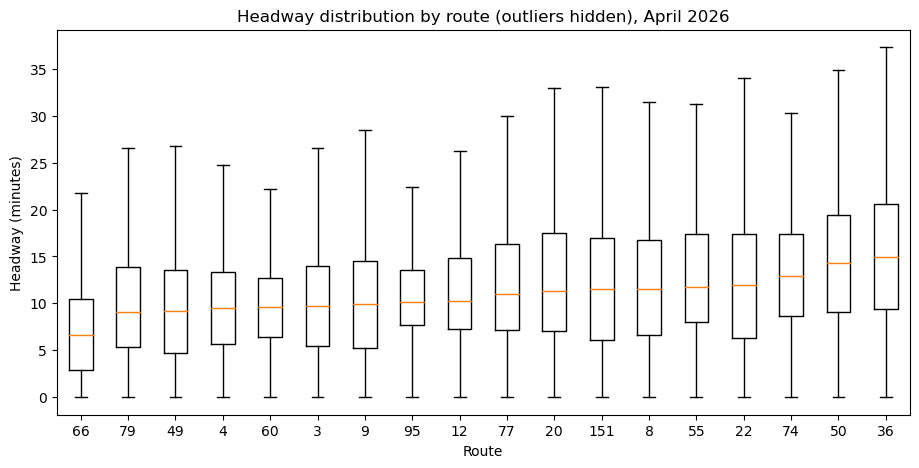

     median  med_lo  med_hi    cv  cv_lo  cv_hi
rt                                             
66     6.61    6.35    7.00  0.76   0.73   0.78
79     9.07    8.76    9.43  0.90   0.87   0.93
49     9.23    9.06    9.54  0.65   0.64   0.67
4      9.47    9.35    9.63  0.58   0.56   0.59
60     9.66    9.47    9.81  0.52   0.51   0.53
3      9.69    9.30   10.07  0.62   0.60   0.64
9      9.96    9.72   10.21  0.73   0.70   0.75
95    10.19   10.07   10.38  0.64   0.61   0.66
12    10.21   10.09   10.34  0.77   0.72   0.83
77    10.98   10.66   11.56  0.75   0.72   0.76
20    11.35   10.77   12.31  0.79   0.75   0.82
151   11.52   11.20   11.85  0.67   0.64   0.70
8     11.58   10.88   12.38  0.63   0.60   0.65
55    11.79   11.41   12.46  0.76   0.71   0.78
22    11.95   11.60   12.43  0.70   0.67   0.73
74    12.92   12.65   13.30  0.55   0.53   0.57
50    14.27   13.67   15.06  0.56   0.54   0.59
36    14.98   14.81   15.26  0.56   0.54   0.58


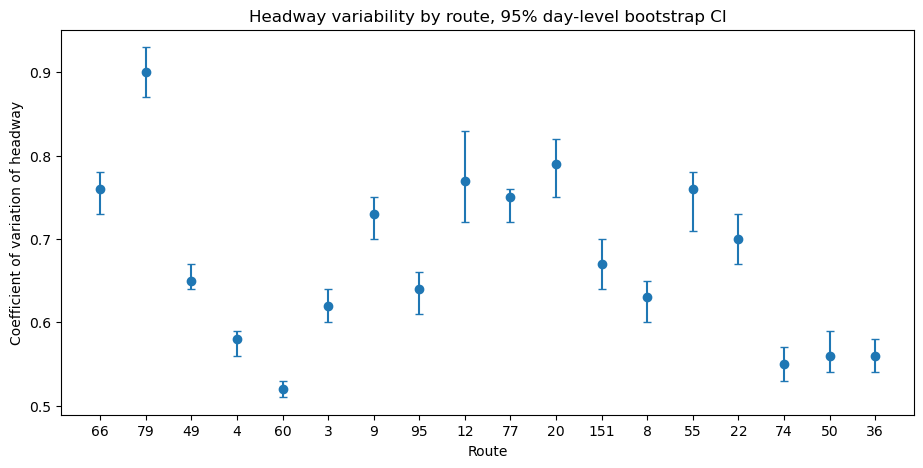

In [26]:
import matplotlib.pyplot as plt

order = route_tbl.sort_values("median").index.tolist()

# --- boxplot of headways (clipped view) ---
fig, ax = plt.subplots(figsize=(11, 5))
data = [an.loc[an["rt"] == r, "headway_min"] for r in order]
ax.boxplot(data, labels=order, showfliers=False)
ax.set_xlabel("Route"); ax.set_ylabel("Headway (minutes)")
ax.set_title("Headway distribution by route (outliers hidden), April 2026")
plt.show()

# --- cluster bootstrap by day: CIs for median and CV ---
rng = np.random.default_rng(42)
rows = []
for rt, g in an.groupby("rt"):
    days = {d: x["headway_min"].to_numpy() for d, x in g.groupby("date")}
    keys = list(days)
    stats = []
    for _ in range(1000):
        pick = rng.integers(0, len(keys), len(keys))
        h = np.concatenate([days[keys[i]] for i in pick])
        stats.append((np.median(h), h.std() / h.mean()))
    s = np.array(stats)
    rows.append({"rt": rt,
                 "median": np.median(an.loc[an.rt == rt, "headway_min"]),
                 "med_lo": np.percentile(s[:, 0], 2.5), "med_hi": np.percentile(s[:, 0], 97.5),
                 "cv": an.loc[an.rt == rt, "headway_min"].std() / an.loc[an.rt == rt, "headway_min"].mean(),
                 "cv_lo": np.percentile(s[:, 1], 2.5), "cv_hi": np.percentile(s[:, 1], 97.5)})
ci = pd.DataFrame(rows).set_index("rt").loc[order].round(2)
print(ci)

# --- CV with 95% CI ---
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ci))
ax.errorbar(x, ci["cv"], yerr=[ci["cv"] - ci["cv_lo"], ci["cv_hi"] - ci["cv"]], fmt="o", capsize=3)
ax.set_xticks(x); ax.set_xticklabels(ci.index)
ax.set_xlabel("Route"); ax.set_ylabel("Coefficient of variation of headway")
ax.set_title("Headway variability by route, 95% day-level bootstrap CI")
plt.show()

### Cell 25: Route 79 coverage check
Shows how many buses per day pass the reference stop in each hour, for Route 79 and for Route 60 as a clean comparison. Also lists all of Route 79's patterns in the catalog.

**Result:** Route 60 sees about 6 buses an hour all day, while Route 79 drops to 0.1 to 1 bus per hour at midday. So buses are missing from the data. Route 79 also has other busy patterns that were not selected. **Route 79 is excluded** from the reliability comparison.

In [27]:
# Average buses observed per day, per hour, per pattern: Route 79 vs a clean route (60)
for rt in ["79", "60"]:
    r = ref[ref["rt"] == rt]
    n_days = r["date"].nunique()
    print(f"\nRoute {rt}: avg buses per day at the reference stop")
    print((r.groupby(["hour", "pid"]).size().unstack() / n_days).round(1))

print()
print(catalog[catalog["rt"] == "79"][["pid", "trips", "first", "last", "trips_per_day"]])


Route 79: avg buses per day at the reference stop
pid   1599  1612
hour            
0      0.7   6.5
1      NaN   0.4
2      NaN   0.0
4      2.1   NaN
5      2.2   3.5
6      NaN   7.4
7      5.4   0.2
8      6.4   2.1
9      7.3   5.5
10     2.9   6.2
11     2.0   1.7
12     1.1   0.9
13     0.3   0.3
14     0.1   0.1
15     0.2   0.9
16     3.4   0.2
17     2.5   1.0
18     0.8   3.9
19     1.0   0.1
20     2.3   1.2
21     1.6   1.1
22     2.0   2.4
23     3.0   3.3

Route 60: avg buses per day at the reference stop
pid   1345  1350
hour            
0      NaN   1.0
1      NaN   0.1
4      0.8   NaN
5      5.2   1.5
6      5.4   4.9
7      7.0   5.0
8      6.8   6.9
9      6.2   7.5
10     5.9   6.3
11     5.9   6.0
12     5.7   6.2
13     6.0   5.6
14     6.3   6.1
15     6.5   6.2
16     6.8   6.1
17     6.1   6.8
18     6.5   6.5
19     5.9   5.9
20     6.2   6.2
21     3.9   5.0
22     2.8   3.4
23     1.2   3.8

       pid   trips       first        last  trips_per_day
66    

## Part D. Are routes different? (Investigation 2)
### Cell 26: normalized headways and a pattern-day table
Divides each headway by its pattern's usual headway (`h_ratio`, where 1.0 means "as expected", 0.2 is bunching and 2.5 is a big gap). Then summarizes **one row per pattern per day**: SD of the ratio (`ratio_sd`), CV, bunching and big-gap rates. Pattern-days with fewer than 20 headways are dropped.

**Why normalize:** raw headways mostly reflect how often a route is *scheduled* to run (Route 66 about every 6.6 min, Route 36 every 15). A plain ANOVA on raw headways would just confirm that schedules differ. Normalizing measures *irregularity relative to schedule*.

**Result:** 993 pattern-days. Route 12's raw CV of 0.78 falls to a normalized 0.55, so its raw figure was inflated by schedule differences across the day.

In [28]:
an["pat_med"] = an.groupby(["pid", "day_type", "time_period"], observed=True)["headway_min"].transform("median")
an["h_ratio"] = an["headway_min"] / an["pat_med"]

day = (an.groupby(["rt", "pid", "date", "day_type"], observed=True)
         .agg(n=("headway_min", "size"),
              mean_h=("headway_min", "mean"),
              sd_h=("headway_min", "std"),
              ratio_sd=("h_ratio", "std"),
              bunched=("bunched", "mean"),
              big_gap=("big_gap", "mean"))
         .reset_index())
day = day[day["n"] >= 20].copy()
day["cv"] = day["sd_h"] / day["mean_h"]

print(len(day), "pattern-days")
print(day.groupby("rt")[["cv", "ratio_sd", "bunched", "big_gap"]].mean().round(3).sort_values("ratio_sd"))

993 pattern-days
        cv  ratio_sd  bunched  big_gap
rt                                    
60   0.515     0.512    0.070    0.038
95   0.496     0.513    0.038    0.047
36   0.547     0.545    0.080    0.051
74   0.545     0.546    0.072    0.057
12   0.784     0.546    0.063    0.051
50   0.538     0.549    0.079    0.052
4    0.573     0.590    0.099    0.061
8    0.586     0.623    0.089    0.075
3    0.604     0.675    0.102    0.080
49   0.648     0.676    0.138    0.086
151  0.662     0.707    0.118    0.098
55   0.659     0.731    0.058    0.091
9    0.726     0.750    0.132    0.083
22   0.644     0.756    0.113    0.128
77   0.690     0.787    0.068    0.126
66   0.740     0.834    0.147    0.129
20   0.731     0.974    0.093    0.112
79   0.852     1.013    0.091    0.089


### Cell 27: coverage screen for every route
For each pattern, computes buses per day for each hour (7 am to 7 pm) and the ratio of the worst hour to the median hour. A very low ratio means some hours have few buses, which signals either missing data or a real schedule pattern.

**Result:** Route 79 (0.05), 9 (0.26), 77 (0.30) and 74 (0.39) were flagged. A low ratio alone does not prove missing data, so Cell 30 examines the flagged routes.

In [29]:
cov = (ref[ref["hour"].between(7, 19)]
       .groupby(["rt", "pid", "hour"]).size().div(ref["date"].nunique())
       .rename("buses_per_day").reset_index())
c = cov.groupby(["rt", "pid"])["buses_per_day"].agg(
    low=lambda s: s.min(), med="median").reset_index()
c["low_vs_median"] = (c["low"] / c["med"]).round(2)
c.groupby("rt")["low_vs_median"].min().sort_values().to_frame("worst_hour_vs_median")

,worst_hour_vs_median
rt,
79,0.05
9,0.26
77,0.30
74,0.39
95,0.50
20,0.56
151,0.61
8,0.67
36,0.67


### Cell 28: route-day table and ANOVA assumption checks
Excludes Route 79 and averages the two directions into **one value per route per day**, so the two directions are not treated as independent. Then checks assumptions:
- **Levene's test** for equal variances
- **Shapiro-Wilk** for normality within each route

**Result:** Levene p is effectively 0 (variances differ across routes) and 6 of 17 routes fail normality. That justifies Welch's ANOVA plus a non-parametric check in the next cell.

*Note:* `import pingouin` is no longer needed. Its `welch_anova` failed on an older pandas, and Cell 29 uses `statsmodels` instead. You can delete that import line.

In [31]:
import pingouin as pg   # run: pip install pingouin
from scipy import stats

EXCLUDE = ["79"]   # add "20" here if Cell 24 flags it
rd = (day[~day["rt"].isin(EXCLUDE)]
      .groupby(["rt", "date", "day_type"], observed=True)
      .agg(ratio_sd=("ratio_sd", "mean"),
           bunched=("bunched", "mean"),
           big_gap=("big_gap", "mean"))
      .reset_index())
print(rd.groupby("rt").size().describe())

# Assumption checks on the outcome (ratio_sd), by route
groups = [g["ratio_sd"].values for _, g in rd.groupby("rt")]
print("Levene (equal variances) p =", round(stats.levene(*groups).pvalue, 4))
shapiro_p = rd.groupby("rt")["ratio_sd"].apply(lambda s: stats.shapiro(s).pvalue)
print("Routes failing Shapiro (p<0.05):", int((shapiro_p < 0.05).sum()), "of", len(shapiro_p))

count    17.000000
mean     29.294118
std       1.829095
min      24.000000
25%      30.000000
50%      30.000000
75%      30.000000
max      30.000000
dtype: float64
Levene (equal variances) p = 0.0
Routes failing Shapiro (p<0.05): 6 of 17


### Cell 29: the formal tests (Investigation 2)
- **Welch's ANOVA** (does not assume equal variances).
- **Kruskal-Wallis** (non-parametric check).
- **Post-hoc:** pairwise Welch t-tests between every route pair, with **Holm correction** for multiple comparisons.

**Result:** Welch F = 37.7 and Kruskal-Wallis H = 274, both with p < 1e-48. 84 of 136 route pairs differ after correction. *(Re-run on the final data in Cell 46.)*

In [33]:
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from itertools import combinations

routes = sorted(rd["rt"].unique())
groups = [rd.loc[rd["rt"] == r, "ratio_sd"].values for r in routes]

# 1) Welch's ANOVA (does not assume equal variances)
w = anova_oneway(groups, use_var="unequal", welch_correction=True)
print(f"Welch ANOVA: F = {w.statistic:.2f}, p = {w.pvalue:.2e}")

# 2) Kruskal-Wallis (non-parametric check)
kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.2e}")

# 3) Post-hoc: pairwise Welch t-tests with Holm correction
rows = []
for a, b in combinations(routes, 2):
    ga = rd.loc[rd["rt"] == a, "ratio_sd"]
    gb = rd.loc[rd["rt"] == b, "ratio_sd"]
    t = stats.ttest_ind(ga, gb, equal_var=False)
    rows.append({"A": a, "B": b, "diff": ga.mean() - gb.mean(), "p": t.pvalue})

ph = pd.DataFrame(rows)
ph["p_holm"] = multipletests(ph["p"], method="holm")[1]
n_sig = (ph["p_holm"] < 0.05).sum()
print(f"\n{n_sig} of {len(ph)} route pairs differ at the 5% level (Holm-adjusted)")
print(ph.sort_values("p_holm").head(15).round(4).to_string(index=False))

Welch ANOVA: F = 37.66, p = 1.31e-48
Kruskal-Wallis: H = 273.98, p = 6.08e-49

84 of 136 route pairs differ at the 5% level (Holm-adjusted)
  A  B    diff   p  p_holm
 49 60  0.1642 0.0     0.0
 60  9 -0.2386 0.0     0.0
 36  9 -0.2049 0.0     0.0
 74  9 -0.2044 0.0     0.0
 60 66 -0.3220 0.0     0.0
 50  9 -0.2013 0.0     0.0
 36 66 -0.2884 0.0     0.0
 66 74  0.2879 0.0     0.0
 50 66 -0.2848 0.0     0.0
151 60  0.1952 0.0     0.0
 12 66 -0.2878 0.0     0.0
  4  9 -0.1606 0.0     0.0
 66 95  0.3097 0.0     0.0
 36 49 -0.1306 0.0     0.0
 49 74  0.1301 0.0     0.0


### Cell 30: diagnose Routes 9, 77 and 74
Shows buses per hour per direction for these three routes, plus the share of 60+ minute gaps for every route.

**Result:** Route 74 runs a steady 4 to 6 buses an hour all day, so its low ratio was just quiet first and last hours, and it is kept. Routes 9 and 77 show hours where one direction has about 1 bus per hour while the opposite direction has about 6, which real service does not do, so they are treated as coverage problems and excluded.

In [34]:
n_days = ref["date"].nunique()
for rt in ["9", "77", "74"]:
    r = ref[(ref["rt"] == rt) & ref["hour"].between(6, 21)]
    print(f"\nRoute {rt}: avg buses per day per hour at the reference stop")
    print((r.groupby(["hour", "pid"]).size().unstack() / n_days).round(1))

print("\n% of headways that are 60+ min gaps, by route:")
print((df_h.groupby("rt")["service_gap"].mean() * 100).round(1).sort_values(ascending=False))


Route 9: avg buses per day per hour at the reference stop
pid   9372  9717
hour            
6      4.4   0.9
7      1.3   0.9
8      1.7   3.6
9      1.6   6.4
10     5.2   5.9
11     5.8   5.8
12     6.2   5.4
13     6.7   3.2
14     6.6   3.1
15     3.4   1.5
16     2.9   1.7
17     1.7   1.6
18     1.5   4.5
19     2.1   6.7
20     6.0   6.1
21     4.9   5.6

Route 77: avg buses per day per hour at the reference stop
pid   10902  10944
hour              
6       4.8    4.6
7       5.2    4.4
8       5.6    3.9
9       5.1    3.0
10      1.9    4.8
11      1.2    1.9
12      0.9    6.2
13      1.1    6.9
14      2.6    3.5
15      4.0    2.1
16      4.8    1.9
17      3.3    4.3
18      1.4    3.6
19      0.8    1.1
20      1.2    4.9
21      2.9    4.4

Route 74: avg buses per day per hour at the reference stop
pid   8420  8422
hour            
6      2.7   3.0
7      5.0   1.8
8      4.3   5.5
9      5.3   4.7
10     4.4   5.4
11     4.5   4.6
12     4.7   4.7
13     4.7   4.6
14 

### Cell 31: sensitivity analysis
Re-runs Welch ANOVA and computes an effect size (**eta-squared**) three ways: all 17 routes, excluding 9 and 77, and also excluding 74. Prints the three most and least regular routes in each case.

**Result:** F stays between 35 and 38 with p < 1e-39, and eta-squared is 0.52 to 0.55 (route explains over half the variation). The same routes stay at the extremes in all three versions, so the conclusion is robust. Routes 60, 95 and 36 are the most regular, and Routes 55, 66 and 20 the least.

In [35]:
def run(excl):
    d = rd[~rd["rt"].isin(excl)]
    rts = sorted(d["rt"].unique())
    g = [d.loc[d["rt"] == r, "ratio_sd"].values for r in rts]
    w = anova_oneway(g, use_var="unequal", welch_correction=True)
    allv = np.concatenate(g)
    ssb = sum(len(x) * (x.mean() - allv.mean()) ** 2 for x in g)
    sst = ((allv - allv.mean()) ** 2).sum()
    means = d.groupby("rt")["ratio_sd"].mean().sort_values()
    print(f"{len(rts)} routes | Welch F = {w.statistic:.1f}, p = {w.pvalue:.1e} | eta² = {ssb/sst:.2f}")
    print("  most regular:", means.head(3).round(2).to_dict())
    print("  least regular:", means.tail(3).round(2).to_dict())

print("A. all 17 routes (79 already excluded)"); run([])
print("B. also excluding 9 and 77");              run(["9", "77"])
print("C. also excluding 9, 77 and 74");          run(["9", "77", "74"])

A. all 17 routes (79 already excluded)
17 routes | Welch F = 37.7, p = 1.3e-48 | eta² = 0.52
  most regular: {'60': 0.51, '95': 0.52, '36': 0.55}
  least regular: {'55': 0.8, '66': 0.83, '20': 1.05}
B. also excluding 9 and 77
15 routes | Welch F = 34.8, p = 3.6e-41 | eta² = 0.55
  most regular: {'60': 0.51, '95': 0.52, '36': 0.55}
  least regular: {'55': 0.8, '66': 0.83, '20': 1.05}
C. also excluding 9, 77 and 74
14 routes | Welch F = 35.9, p = 2.3e-39 | eta² = 0.55
  most regular: {'60': 0.51, '95': 0.52, '36': 0.55}
  least regular: {'55': 0.8, '66': 0.83, '20': 1.05}


## Part E. Time of day and weekday vs weekend (Investigations 3-4)
### Cell 32: route x day x time-period table
Excludes Routes 79, 9 and 77, builds one row per route, date and time period (averaging the two directions), and requires at least 8 headways per cell.

**Result:** 1,566 rows across 15 routes. Weekday mean regularity by period: AM 0.58, Evening 0.59, Midday 0.64, PM peak 0.74.

In [36]:
EXCLUDE = ["79", "9", "77"]

pdp = (an[~an["rt"].isin(EXCLUDE)]
       .groupby(["rt", "pid", "date", "day_type", "time_period"], observed=True)
       .agg(n=("h_ratio", "size"), ratio_sd=("h_ratio", "std"),
            bunched=("bunched", "mean"), big_gap=("big_gap", "mean"))
       .reset_index())
pdp = pdp[pdp["n"] >= 8]

# average the two directions -> one value per route, day and period
rdp = (pdp.groupby(["rt", "date", "day_type", "time_period"], observed=True)
          [["ratio_sd", "bunched", "big_gap"]].mean().reset_index().dropna())
rdp["time_period"] = rdp["time_period"].astype(str)

print(rdp.shape, "| routes:", rdp["rt"].nunique())
print(rdp.groupby(["day_type", "time_period"])["ratio_sd"].agg(["count", "mean", "median"]).round(3))

(1566, 7) | routes: 15
                          count   mean  median
day_type time_period                          
weekday  AM peak (5-9)      308  0.580   0.562
         Evening (19-22)    267  0.588   0.579
         Midday (9-15)      286  0.642   0.608
         PM peak (15-19)    264  0.743   0.710
weekend  AM peak (5-9)      116  0.392   0.379
         Evening (19-22)    104  0.543   0.526
         Midday (9-15)      116  0.567   0.537
         PM peak (15-19)    105  0.634   0.608


### Cell 33: time of day (Investigation 3)
Four analyses on weekdays:
1. A **regression** with route fixed effects and standard errors **clustered by date** (all routes share a day's weather and events).
2. A two-way ANOVA with a route x period interaction.
3. A **Friedman test** (a non-parametric repeated-measures test: the same route and day across all four periods).
4. A heatmap of mean regularity by route and period.

**Result:** the PM peak is +0.186 higher in variability than the AM peak (CI 0.162 to 0.211), midday is +0.044, evening is not distinguishable. The Friedman test agrees (chi-square about 201).

**Caution (partly superseded):** the two-way ANOVA output in this cell is **not reliable**. It shows p = 1.0 for time period while the regression shows a huge effect, and the cause is that several routes had empty route x period cells, which breaks the Type II calculation. Cell 35 redoes it properly.

                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                             0.5811      0.027     21.605      0.000       0.528       0.634
C(time_period)[T.Evening (19-22)]     0.0228      0.016      1.417      0.156      -0.009       0.054
C(time_period)[T.Midday (9-15)]       0.0439      0.008      5.288      0.000       0.028       0.060
C(time_period)[T.PM peak (15-19)]     0.1864      0.012     14.920      0.000       0.162       0.211
C(rt)[T.151]                          0.0420      0.036      1.151      0.250      -0.029       0.113
C(rt)[T.20]                           0.5178      0.049     10.601      0.000       

Two-way ANOVA (Type II):
                       sum_sq      df        F  PR(>F)
C(rt)                  3.5291    14.0  21.4034  0.0000
C(time_period)         0.0000     3.0   0.0000  1.0000
C(rt):C(ti

/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:1871: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 14, but rank is 12
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/lib/python3.9/site-packages/statsmodels/base/model.py:1871: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 42, but rank is 2
  warnings.warn('covariance of constraints does not have full '


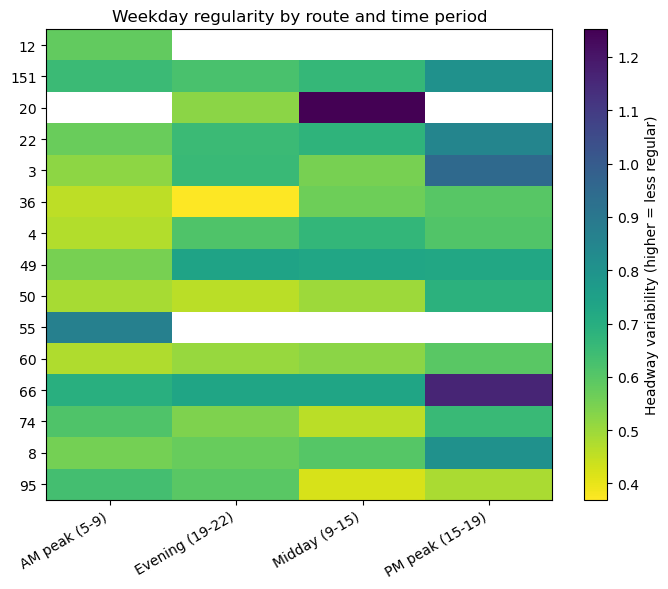

In [37]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

wk = rdp[rdp["day_type"] == "weekday"].copy()

# 1) Period effect with route fixed effects, SEs clustered by date
#    (all routes share the same day's weather, events, etc.)
m = smf.ols("ratio_sd ~ C(time_period) + C(rt)", data=wk).fit(
    cov_type="cluster", cov_kwds={"groups": wk["date"].factorize()[0]})
print(m.summary().tables[1].as_text()[:900])   # first rows: the time_period effects

# 2) Two-way ANOVA with route x period interaction
m2 = smf.ols("ratio_sd ~ C(rt) * C(time_period)", data=wk).fit()
print("\nTwo-way ANOVA (Type II):")
print(anova_lm(m2, typ=2).round(4))

# 3) Non-parametric repeated-measures check (same route and day across periods)
piv = wk.pivot_table(index=["rt", "date"], columns="time_period", values="ratio_sd").dropna()
print("\nFriedman:", stats.friedmanchisquare(*[piv[c] for c in piv.columns]))
print(piv.mean().round(3))

# 4) Route x period heatmap of mean regularity
import matplotlib.pyplot as plt
heat = wk.pivot_table(index="rt", columns="time_period", values="ratio_sd", aggfunc="mean")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(heat.values, aspect="auto", cmap="viridis_r")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, rotation=30, ha="right")
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
plt.colorbar(im, label="Headway variability (higher = less regular)")
ax.set_title("Weekday regularity by route and time period")
plt.tight_layout(); plt.show()

### Cell 34: weekday vs weekend (Investigation 4)
For headway variability, bunching and big gaps, computes the weekday/weekend difference with a 95% CI, Welch t-test, Mann-Whitney test and **Cohen's d** (effect size). Then a conservative paired version: one value per route per day type, compared across routes with a paired t-test and Wilcoxon.

**Result:** weekends looked *more* regular (difference +0.137, d = 0.79), with 14 of 15 routes more regular on weekends. This looked like a large effect, but later cells show it is mostly a **weekday-morning** effect and shrinks on the final data. The row-level p-values are optimistic because routes on the same day are not independent.

In [38]:
rd2 = (rdp.groupby(["rt", "date", "day_type"])[["ratio_sd", "bunched", "big_gap"]]
          .mean().reset_index())

print("Route-days:", rd2["day_type"].value_counts().to_dict(), "\n")
for metric in ["ratio_sd", "bunched", "big_gap"]:
    a = rd2.loc[rd2["day_type"] == "weekday", metric]
    b = rd2.loc[rd2["day_type"] == "weekend", metric]
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var() / len(a) + b.var() / len(b))
    sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
    t = stats.ttest_ind(a, b, equal_var=False)
    mw = stats.mannwhitneyu(a, b)
    print(f"{metric}: weekday {a.mean():.3f}, weekend {b.mean():.3f}, "
          f"diff {diff:+.3f} (95% CI {diff-1.96*se:+.3f} to {diff+1.96*se:+.3f}), "
          f"Welch p={t.pvalue:.3g}, Mann-Whitney p={mw.pvalue:.3g}, Cohen's d={diff/sp:.2f}")

# Conservative version: one number per route per day type, paired across routes
by_route = rd2.groupby(["rt", "day_type"])["ratio_sd"].mean().unstack()
print("\nPaired by route (n =", len(by_route), "):")
print(by_route.round(3))
print("paired t-test:", stats.ttest_rel(by_route["weekday"], by_route["weekend"]))
print("Wilcoxon:", stats.wilcoxon(by_route["weekday"], by_route["weekend"]))

Route-days: {'weekday': 330, 'weekend': 118} 

ratio_sd: weekday 0.671, weekend 0.534, diff +0.137 (95% CI +0.109 to +0.165), Welch p=1.64e-19, Mann-Whitney p=1.26e-15, Cohen's d=0.79
bunched: weekday 0.088, weekend 0.070, diff +0.018 (95% CI +0.009 to +0.027), Welch p=0.000162, Mann-Whitney p=2.46e-05, Cohen's d=0.41
big_gap: weekday 0.084, weekend 0.062, diff +0.022 (95% CI +0.010 to +0.033), Welch p=0.000319, Mann-Whitney p=3.45e-10, Cohen's d=0.46

Paired by route (n = 15 ):
day_type  weekday  weekend
rt                        
12          0.581    0.479
151         0.686    0.653
20          1.184    0.571
22          0.688    0.677
3           0.667    0.470
36          0.500    0.511
4           0.590    0.537
49          0.685    0.611
50          0.532    0.498
55          0.866    0.519
60          0.524    0.457
66          0.830    0.659
74          0.566    0.486
8           0.634    0.462
95          0.534    0.428
paired t-test: Ttest_relResult(statistic=3.31247039723315

### Cell 35: empty-cell check and a proper two-way analysis
Counts days per route and period and keeps only routes with at least 10 days in all four periods. Then compares nested models with F-tests (route only, plus period, plus the route x period interaction).

**Result:** Routes 12, 20 and 55 had almost no weekday data outside one period, which explains the broken ANOVA and is another sign of coverage problems. The final set is **12 routes**: 3, 4, 8, 22, 36, 49, 50, 60, 66, 74, 95 and 151. Period effect F = 109 and interaction F = 16.3, both p < 0.0001. The PM-peak penalty differs a lot by route (Route 66 +0.47 and Route 3 +0.43 versus Route 95 -0.15).

In [39]:
cells = wk.groupby(["rt", "time_period"]).size().unstack(fill_value=0)
print(cells)

# keep routes with at least 10 days in every period
ok = cells[(cells >= 10).all(axis=1)].index
print("\nroutes kept:", len(ok), "of", len(cells), "| dropped:", sorted(set(cells.index) - set(ok)))
wk2 = wk[wk["rt"].isin(ok)]

m_rt  = smf.ols("ratio_sd ~ C(rt)", wk2).fit()
m_add = smf.ols("ratio_sd ~ C(rt) + C(time_period)", wk2).fit()
m_int = smf.ols("ratio_sd ~ C(rt) * C(time_period)", wk2).fit()

print("\nTime-period main effect (adding period to route):")
print(anova_lm(m_rt, m_add).round(4))
print("\nRoute x period interaction:")
print(anova_lm(m_add, m_int).round(4))

heat = wk2.pivot_table(index="rt", columns="time_period", values="ratio_sd")
heat["PM_minus_AM"] = heat["PM peak (15-19)"] - heat["AM peak (5-9)"]
print("\nMean weekday regularity by route and period:")
print(heat.round(2).sort_values("PM_minus_AM", ascending=False))

time_period  AM peak (5-9)  Evening (19-22)  Midday (9-15)  PM peak (15-19)
rt                                                                         
12                      22                0              0                0
151                     22               22             22               22
20                       0                4             22                0
22                      22               22             22               22
3                       22               22             22               22
36                      22               21             22               22
4                       22               22             22               22
49                      22               22             22               22
50                      22               22             22               22
55                      22                0              0                0
60                      22               22             22               22
66          

### Cell 36: weekend effect on the 12 final routes
Fixes the route set (`KEEP`), then estimates an adjusted weekend effect (controlling for route and period, clustered by date) and compares weekday and weekend period by period, paired across routes.

**Result:** overall weekend minus weekday is -0.080 (CI -0.107 to -0.053). The difference is concentrated in the **AM peak** (weekends more regular on all 12 routes, p = 0.0005). Midday and evening show little difference.

In [41]:
KEEP = list(ok)   # the 12 routes with all four weekday periods
rk = rdp[rdp["rt"].isin(KEEP)].copy()
rk["weekend"] = (rk["day_type"] == "weekend").astype(int)

# do these routes have weekend data in all four periods?
print(rk[rk["weekend"] == 1].groupby(["rt", "time_period"]).size().unstack(fill_value=0))

# Adjusted weekend effect: same routes, same period mix, SEs clustered by date
m = smf.ols("ratio_sd ~ weekend + C(time_period) + C(rt)", rk).fit(
    cov_type="cluster", cov_kwds={"groups": rk["date"].factorize()[0]})
lo, hi = m.conf_int().loc["weekend"]
print(f"\nWeekend minus weekday: {m.params['weekend']:+.3f} "
      f"(95% CI {lo:+.3f} to {hi:+.3f}), p = {m.pvalues['weekend']:.2g}   [negative = more regular on weekends]")

# Period by period, paired across routes
by = rk.groupby(["rt", "time_period", "day_type"])["ratio_sd"].mean().unstack()
by["diff"] = by["weekday"] - by["weekend"]       # positive = weekdays less regular
print("\nWeekday minus weekend, by route and period:")
print(by["diff"].unstack().round(2))
for p, g in by.groupby(level="time_period"):
    d = g["diff"].dropna()
    print(f"{p}: mean diff {d.mean():+.3f}, weekends more regular on "
          f"{int((d > 0).sum())}/{len(d)} routes, Wilcoxon p = {stats.wilcoxon(d).pvalue:.3g}")

time_period  AM peak (5-9)  Evening (19-22)  Midday (9-15)  PM peak (15-19)
rt                                                                         
151                      8                8              8                8
22                       8                4              8                4
3                        7                8              8                8
36                       8                8              8                8
4                        8                8              8                8
49                       8                8              8                8
50                       8                8              8                8
60                       8                8              8                8
66                       8                8              8                8
74                       8                8              8                8
8                        8                4              8                5
95          

## Part F. Speed as a congestion proxy and weather (Investigation 5)
### Cell 37: what does `speed_mph` mean?
Summarizes speed, checks how many distinct speed values a trip carries per stop, and looks at speed by period, day type and route.

**Results:**
- Each speed value is shared across roughly 6 stops (distinct speeds per stop is about 0.17), so it is a *segment* speed from consecutive pings, not a per-stop measurement.
- Median speed is about 11.6 mph, which is plausible for city buses.
- Speed is slowest at the weekday PM peak (10.3 mph) and faster on weekends, which fits congestion.
- Speed differs across routes for structural reasons, so we can only compare *within* a route.

It is a rough proxy: speed also reflects stop spacing, signals and boarding, not just traffic.

In [42]:
print(ref["speed_mph"].describe(percentiles=[.01, .05, .5, .95, .99]).round(2))

# How many distinct speed values does a trip carry? (1.0 = every stop different; low = shared across stops)
ids = raw["unique_trip_vehicle_day"].drop_duplicates().sample(2000, random_state=1)
samp = raw[raw["unique_trip_vehicle_day"].isin(ids)]
g = samp.groupby("unique_trip_vehicle_day", observed=True)
print("\nDistinct speeds / stops per trip:")
print((g["speed_mph"].nunique() / g.size()).describe().round(2))

print("\nMean speed by time period and day type (reference stops):")
print(ref.groupby(["day_type", "time_period"], observed=True)["speed_mph"].mean().round(2).unstack())

print("\nMean speed by route:")
print(ref.groupby("rt")["speed_mph"].mean().round(1).sort_values())

count    90608.00
mean        11.99
std          3.82
min          1.00
1%           4.41
5%           6.46
50%         11.63
95%         18.70
99%         22.98
max         55.35
Name: speed_mph, dtype: float64

Distinct speeds / stops per trip:
count    2000.00
mean        0.17
std         0.05
min         0.01
25%         0.14
50%         0.17
75%         0.20
max         0.30
dtype: float64

Mean speed by time period and day type (reference stops):
time_period  AM peak (5-9)  Midday (9-15)  PM peak (15-19)  Evening (19-22)
day_type                                                                   
weekday              12.23          11.09            10.28            12.40
weekend              14.17          11.97            11.99            13.02

Mean speed by route:
rt
36      8.7
50     10.3
74     10.6
22     10.8
151    11.1
8      11.3
66     11.3
79     12.0
4      12.1
60     12.2
49     12.3
77     12.8
20     12.9
55     13.6
9      13.8
12     13.9
3      13.9
95     14.

### Cell 38: robustness check, normalizing by hour
Previously headways were normalized by each pattern's median over a whole period (such as 5 am to 9 am). But scheduled headways change *within* a period, for example the ramp-up at the start of service. This cell normalizes by **hour** instead, and re-runs the time-of-day and weekend analyses. It also defines `cl()`, a helper for date-clustered standard errors used from here on.

**Result:** the PM-peak effect holds (+0.203), the overall weekend effect holds (-0.077), and the AM weekend gap holds. The earlier PM-peak weekend gap largely disappears, so part of it was a schedule-ramp artifact.

In [43]:
an["pat_med_hr"] = an.groupby(["pid", "day_type", "hour"], observed=True)["headway_min"].transform("median")
an["h_ratio_hr"] = an["headway_min"] / an["pat_med_hr"]

p2 = (an[an["rt"].isin(KEEP)]
      .groupby(["rt", "pid", "date", "day_type", "time_period"], observed=True)
      .agg(n=("h_ratio_hr", "size"), ratio_sd=("h_ratio_hr", "std"))
      .reset_index())
p2 = p2[p2["n"] >= 8]

r2 = (p2.groupby(["rt", "date", "day_type", "time_period"], observed=True)["ratio_sd"]
        .mean().reset_index().dropna())
r2["time_period"] = r2["time_period"].astype(str)
r2["weekend"] = (r2["day_type"] == "weekend").astype(int)
print(r2.shape)

def cl(d):
    return dict(cov_type="cluster", cov_kwds={"groups": d["date"].factorize()[0]})

# Time of day (weekdays): is the PM peak still the worst?
wkh = r2[r2["weekend"] == 0]
m = smf.ols("ratio_sd ~ C(time_period, Treatment('AM peak (5-9)')) + C(rt)", wkh).fit(**cl(wkh))
out = pd.concat([m.params, m.conf_int()], axis=1)
out.columns = ["coef", "lo", "hi"]
print(out.filter(like="time_period", axis=0).round(3))

# Weekend effect overall, then by period
mw = smf.ols("ratio_sd ~ weekend + C(time_period) + C(rt)", r2).fit(**cl(r2))
lo, hi = mw.conf_int().loc["weekend"]
print(f"\nWeekend minus weekday: {mw.params['weekend']:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

by = r2.groupby(["rt", "time_period", "day_type"])["ratio_sd"].mean().unstack()
by["diff"] = by["weekday"] - by["weekend"]
for p, g in by.groupby(level="time_period"):
    d = g["diff"].dropna()
    print(f"{p}: mean diff {d.mean():+.3f}, weekends more regular on {int((d > 0).sum())}/{len(d)}, "
          f"Wilcoxon p = {stats.wilcoxon(d).pvalue:.3g}")

(1414, 6)
                                                     coef     lo     hi
C(time_period, Treatment('AM peak (5-9)'))[T.Ev...  0.048  0.015  0.082
C(time_period, Treatment('AM peak (5-9)'))[T.Mi...  0.049  0.031  0.068
C(time_period, Treatment('AM peak (5-9)'))[T.PM...  0.203  0.175  0.231

Weekend minus weekday: -0.077 (95% CI -0.103 to -0.051)
AM peak (5-9): mean diff +0.197, weekends more regular on 12/12, Wilcoxon p = 0.000488
Evening (19-22): mean diff +0.051, weekends more regular on 9/12, Wilcoxon p = 0.151
Midday (9-15): mean diff +0.004, weekends more regular on 8/12, Wilcoxon p = 0.622
PM peak (15-19): mean diff +0.050, weekends more regular on 6/12, Wilcoxon p = 0.622


### Cell 39: speed and regularity (Investigation 5)
Builds the average speed per route, date and period, merges it with regularity, and estimates how regularity changes per +1 mph. Three versions: pooled, with route fixed effects, and adding period and weekend. It also compares slow, medium and fast days defined **relative to each route's own speed**, an analogue of low/medium/high traffic.

**Result:** with route effects, +1 mph goes with -0.094 in variability, and -0.079 after adjusting for period and weekend. Regularity is 0.659 on slow days, 0.599 on medium days and 0.537 on fast days. The pooled estimate (-0.036) is weaker because it mixes in between-route differences.

**Cautions:** reverse causation is possible (bunching slows buses), and an association is not proof of traffic causing irregularity.

In [44]:
labels = ["AM peak (5-9)", "Midday (9-15)", "PM peak (15-19)", "Evening (19-22)"]

raw2 = raw[raw["rt"].astype(str).isin(KEEP)].copy()
raw2["rt"] = raw2["rt"].astype(str)
raw2["date"] = raw2["bus_stop_time"].dt.normalize()
raw2["time_period"] = pd.cut(raw2["bus_stop_time"].dt.hour, bins=[5, 9, 15, 19, 22],
                             right=False, labels=labels).astype(str)
spd = (raw2[raw2["time_period"] != "nan"]
       .groupby(["rt", "date", "time_period"])["speed_mph"].mean()
       .rename("speed").reset_index())

d5 = r2.merge(spd, on=["rt", "date", "time_period"])
print(d5.shape)

# Correlations (pooled; between-route differences are included here)
print("Pearson r:", round(d5["speed"].corr(d5["ratio_sd"]), 3),
      "| Spearman rho:", round(d5["speed"].corr(d5["ratio_sd"], method="spearman"), 3))

# Regressions: speed effect per +1 mph, SEs clustered by date
for name, f in [("pooled", "ratio_sd ~ speed"),
                ("+ route fixed effects", "ratio_sd ~ speed + C(rt)"),
                ("+ period + weekend", "ratio_sd ~ speed + C(rt) + C(time_period) + weekend")]:
    m = smf.ols(f, d5).fit(**cl(d5))
    lo, hi = m.conf_int().loc["speed"]
    print(f"{name}: +1 mph -> {m.params['speed']:+.3f} (95% CI {lo:+.3f} to {hi:+.3f}), p = {m.pvalues['speed']:.2g}")

# Slow / medium / fast days, defined relative to each route's own speed in that period
d5["pct"] = d5.groupby(["rt", "time_period"])["speed"].rank(pct=True)
d5["speed_level"] = pd.cut(d5["pct"], [0, 1/3, 2/3, 1], labels=["slow", "medium", "fast"], include_lowest=True)
print("\nMean regularity by relative speed (same route, same period):")
print(d5.groupby("speed_level", observed=True)["ratio_sd"].agg(["count", "mean"]).round(3))

(1414, 7)
Pearson r: -0.324 | Spearman rho: -0.308
pooled: +1 mph -> -0.036 (95% CI -0.043 to -0.030), p = 6.8e-28
+ route fixed effects: +1 mph -> -0.094 (95% CI -0.101 to -0.087), p = 8.3e-150
+ period + weekend: +1 mph -> -0.079 (95% CI -0.098 to -0.059), p = 8.1e-16

Mean regularity by relative speed (same route, same period):
             count   mean
speed_level              
slow           466  0.659
medium         474  0.599
fast           474  0.537


### Cell 40: weather (April only)
Downloads daily Chicago weather (precipitation and temperature) from the free Open-Meteo archive, defines a rainy day as at least 1 mm, merges it in, and tests whether rain slows buses or reduces regularity, and whether the speed effect survives accounting for weather.

**Result:** rain has no detectable effect on speed (+0.008 mph, CI -0.10 to +0.12) or regularity (+0.002), and the speed effect is unchanged (-0.077 per mph). *(Re-done on three months with a stricter rain definition in Cell 43.)* Daily totals cannot tell whether it rained during rush hour, so this is a fairly weak weather test.

In [45]:
url = ("https://archive-api.open-meteo.com/v1/archive?latitude=41.88&longitude=-87.63"
       "&start_date=2026-04-01&end_date=2026-04-30"
       "&daily=precipitation_sum,temperature_2m_mean,wind_speed_10m_max"
       "&timezone=America%2FChicago")
w = requests.get(url, timeout=60).json()["daily"]
wx = pd.DataFrame(w).rename(columns={"time": "date", "precipitation_sum": "precip_mm",
                                     "temperature_2m_mean": "temp_c",
                                     "wind_speed_10m_max": "wind_kmh"})
wx["date"] = pd.to_datetime(wx["date"])
wx["rain"] = (wx["precip_mm"] >= 1).astype(int)
print(wx.describe().round(1))
print(wx["rain"].sum(), "rainy days (>= 1 mm)")

d6 = d5.merge(wx[["date", "rain", "precip_mm", "temp_c"]], on="date")
print(d6.shape)

def show(m, names):
    ci = m.conf_int()
    for n in names:
        print(f"  {n}: {m.params[n]:+.3f} (95% CI {ci.loc[n,0]:+.3f} to {ci.loc[n,1]:+.3f}), p = {m.pvalues[n]:.2g}")

ctrl = "C(rt) + C(time_period) + weekend"
print("\nDoes rain slow buses? (speed in mph)")
show(smf.ols(f"speed ~ rain + {ctrl}", d6).fit(**cl(d6)), ["rain"])

print("\nDoes rain reduce regularity? (headway variability)")
show(smf.ols(f"ratio_sd ~ rain + {ctrl}", d6).fit(**cl(d6)), ["rain"])

print("\nSpeed effect after accounting for weather:")
show(smf.ols(f"ratio_sd ~ speed + rain + temp_c + {ctrl}", d6).fit(**cl(d6)), ["speed", "rain", "temp_c"])

# how big is a typical speed swing within a route and period?
d6["speed_dm"] = d6["speed"] - d6.groupby(["rt", "time_period"])["speed"].transform("mean")
print("\nSD of speed within route-period (mph):", round(d6["speed_dm"].std(), 2))

       precip_mm  temp_c  wind_kmh  rain
count       30.0    30.0      30.0  30.0
mean         5.5    11.6      21.4   0.6
std          8.6     5.3       4.8   0.5
min          0.0     0.7      13.8   0.0
25%          0.1     7.3      17.6   0.0
50%          1.8    10.4      22.0   1.0
75%          5.1    15.6      24.8   1.0
max         30.8    21.0      32.3   1.0
18 rainy days (>= 1 mm)
(1414, 12)

Does rain slow buses? (speed in mph)
  rain: +0.008 (95% CI -0.103 to +0.120), p = 0.88

Does rain reduce regularity? (headway variability)
  rain: +0.002 (95% CI -0.020 to +0.024), p = 0.86

Speed effect after accounting for weather:
  speed: -0.077 (95% CI -0.097 to -0.058), p = 6.3e-15
  rain: -0.001 (95% CI -0.016 to +0.014), p = 0.91
  temp_c: +0.002 (95% CI -0.000 to +0.003), p = 0.11

SD of speed within route-period (mph): 0.53


### Cell 41: plot of speed vs regularity
Subtracts each route-period's average speed and regularity (so Route 36 being slow does not matter) and plots day-to-day deviations as a scatter with decile means on top.

**Expected shape:** a downward slope, with slower-than-usual days sitting above zero on the vertical axis. A typical day-to-day speed swing is only about 0.5 mph, so the practical effect is small compared with time of day.

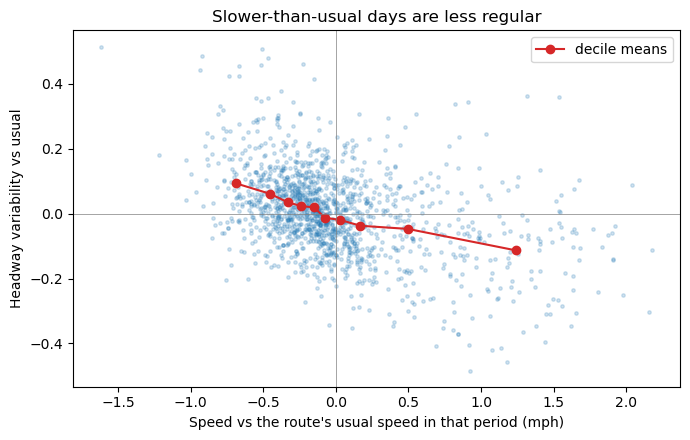

In [46]:
d6["reg_dm"] = d6["ratio_sd"] - d6.groupby(["rt", "time_period"])["ratio_sd"].transform("mean")
d6["bin"] = pd.qcut(d6["speed_dm"], 10)
b = d6.groupby("bin", observed=True)[["speed_dm", "reg_dm"]].mean()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(d6["speed_dm"], d6["reg_dm"], s=6, alpha=0.2)
ax.plot(b["speed_dm"], b["reg_dm"], "o-", color="C3", label="decile means")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("Speed vs the route's usual speed in that period (mph)")
ax.set_ylabel("Headway variability vs usual")
ax.set_title("Slower-than-usual days are less regular")
ax.legend(); plt.tight_layout(); plt.show()

## Part G. Final three-month dataset
### Cell 42: memory-safe loader for April to June 2026
Widens the window to three months. A full load would be about 22 million rows, so `process_pattern()` handles **one pattern at a time** and immediately reduces it to what is needed:
- speed totals and counts per date and period (from all stops)
- headways at the reference stop, with 60+ minute gaps and duplicate-vehicle rows removed
- normalized ratios (by period and by hour) and the bunched and big-gap flags
- a pattern-day-period summary

The three outputs are `pdp2` (summary), `sp2` (speed) and `hw` (headway-level rows).

**Result:** 91 days (26 weekend days) and 185,851 clean headways across 24 patterns (12 routes). This gives about 91 effectively independent days instead of 30.

In [47]:
START, END = pd.Timestamp("2026-04-01"), pd.Timestamp("2026-07-01")
COLS = ["rt", "vid", "stpid", "stop_sequence", "bus_stop_time", "speed_mph"]
labels = ["AM peak (5-9)", "Midday (9-15)", "PM peak (15-19)", "Evening (19-22)"]
mid_seq = mid.to_dict()        # reference stop per pattern, from the April run

def process_pattern(pid, rt):
    x = pd.read_parquet(DATA_DIR / f"trips_{pid}_full.parquet", columns=COLS,
                        filters=[("bus_stop_time", ">=", START), ("bus_stop_time", "<", END)])
    x["date"] = x["bus_stop_time"].dt.normalize()
    x["hour"] = x["bus_stop_time"].dt.hour
    x["time_period"] = pd.cut(x["hour"], bins=[5, 9, 15, 19, 22], right=False, labels=labels)

    # speed: sum and count per date and period (all stops)
    sp = (x.dropna(subset=["time_period"])
            .groupby(["date", "time_period"], observed=True)["speed_mph"]
            .agg(["sum", "count"]).reset_index())
    sp["rt"], sp["pid"] = rt, pid

    # reference stop -> headways
    r = x[x["stop_sequence"] == mid_seq[pid]].sort_values("bus_stop_time").copy()
    r["headway_min"] = r.groupby("date")["bus_stop_time"].diff().dt.total_seconds() / 60
    r["prev_vid"] = r.groupby("date")["vid"].shift()
    r["day_type"] = np.where(r["bus_stop_time"].dt.dayofweek >= 5, "weekend", "weekday")
    r = r.dropna(subset=["headway_min", "time_period"])
    r = r[(r["headway_min"] <= 60) & (r["vid"] != r["prev_vid"])].copy()
    r["time_period"] = r["time_period"].astype(str)

    med_p = r.groupby(["day_type", "time_period"])["headway_min"].transform("median")
    med_h = r.groupby(["day_type", "hour"])["headway_min"].transform("median")
    r["h_ratio"], r["h_ratio_hr"] = r["headway_min"] / med_p, r["headway_min"] / med_h
    r["bunched"] = r["headway_min"] < 0.25 * med_p
    r["big_gap"] = r["headway_min"] > 2.0 * med_p
    r["rt"], r["pid"] = rt, pid

    agg = (r.groupby(["date", "day_type", "time_period"])
             .agg(n=("h_ratio", "size"), ratio_sd=("h_ratio", "std"),
                  ratio_sd_hr=("h_ratio_hr", "std"),
                  bunched=("bunched", "mean"), big_gap=("big_gap", "mean")).reset_index())
    agg["rt"], agg["pid"] = rt, pid
    return agg, sp, r[["rt", "pid", "date", "hour", "day_type", "time_period",
                       "headway_min", "h_ratio", "h_ratio_hr", "bunched", "big_gap"]]

sel_final = sel2[sel2["rt"].isin(KEEP)]
aggs, sps, hws = [], [], []
for _, row in sel_final.iterrows():
    a, s, h = process_pattern(int(row["pid"]), str(row["rt"]))
    aggs.append(a); sps.append(s); hws.append(h)
    print("done", row["rt"], row["pid"], len(h))

pdp2 = pd.concat(aggs, ignore_index=True)
sp2  = pd.concat(sps,  ignore_index=True)
hw   = pd.concat(hws,  ignore_index=True)
print(pdp2.shape, sp2.shape, hw.shape)
print("days:", pdp2["date"].nunique(), "| weekend days:",
      pdp2.loc[pdp2["day_type"] == "weekend", "date"].nunique())

done 151 8102 7599
done 151 6414 7007
done 22 3936 6337
done 22 3932 6959
done 3 18415 8344
done 3 18414 8642
done 36 5905 6621
done 36 5907 5015
done 4 19378 9072
done 4 19379 8923
done 49 1178 9369
done 49 1180 9590
done 50 1192 5768
done 50 1151 6042
done 60 1345 9247
done 60 1350 8856
done 66 6665 11991
done 66 6662 12582
done 74 8420 6828
done 74 8422 6710
done 8 9368 7187
done 8 9376 7050
done 95 10956 7546
done 95 8147 2566
(8616, 10) (8730, 6) (185851, 11)
days: 91 | weekend days: 26


### Cell 43: key results re-run on three months
Repeats the main analyses on the larger dataset, using the hour-normalized measure:
1. Time-of-day effects on weekdays.
2. The weekend effect, overall and by period.
3. Speed and weather (downloads April to June weather and defines a rainy day as at least 5 mm).

**Result:**
- PM peak vs AM peak: **+0.254** (CI +0.232 to +0.275), bigger than in April.
- Weekend minus weekday: **-0.035** (CI -0.061 to -0.009), half the April estimate. It is driven almost entirely by weekday mornings (12 of 12 routes more regular on weekend mornings). Midday, evening and PM show no clear difference.
- Speed: **-0.091 per mph** (CI -0.113 to -0.069), stable.
- Rain (at least 5 mm): -0.003 (CI -0.029 to +0.022), no detectable effect.

This cell redefines `spd` and `wx`, which later cells use.

In [48]:
pdp2 = pdp2[pdp2["n"] >= 8]
rdp2 = (pdp2.groupby(["rt", "date", "day_type", "time_period"])
              [["ratio_sd", "ratio_sd_hr", "bunched", "big_gap"]].mean().reset_index().dropna())
rdp2["weekend"] = (rdp2["day_type"] == "weekend").astype(int)

cells = rdp2[rdp2.weekend == 0].groupby(["rt", "time_period"]).size().unstack(fill_value=0)
print("weekday days per route and period (min):", int(cells.values.min()))

# 1) Time of day (weekdays), hour-normalized
wk3 = rdp2[rdp2.weekend == 0]
m = smf.ols("ratio_sd_hr ~ C(time_period, Treatment('AM peak (5-9)')) + C(rt)", wk3).fit(**cl(wk3))
ci = m.conf_int()
for n in m.params.index:
    if "time_period" in n:
        print(f"{n.split('[T.')[1][:-1]}: {m.params[n]:+.3f} (95% CI {ci.loc[n,0]:+.3f} to {ci.loc[n,1]:+.3f})")

# 2) Weekend effect overall and by period
mw = smf.ols("ratio_sd_hr ~ weekend + C(time_period) + C(rt)", rdp2).fit(**cl(rdp2))
lo, hi = mw.conf_int().loc["weekend"]
print(f"\nWeekend minus weekday: {mw.params['weekend']:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")
by = rdp2.groupby(["rt", "time_period", "day_type"])["ratio_sd_hr"].mean().unstack()
by["diff"] = by["weekday"] - by["weekend"]
for p, g in by.groupby(level="time_period"):
    d = g["diff"].dropna()
    print(f"{p}: mean diff {d.mean():+.3f}, weekends more regular on {int((d > 0).sum())}/{len(d)}, "
          f"Wilcoxon p = {stats.wilcoxon(d).pvalue:.3g}")

# 3) Speed and weather
spd = sp2.groupby(["rt", "date", "time_period"]).agg(s=("sum", "sum"), c=("count", "sum")).reset_index()
spd["speed"] = spd["s"] / spd["c"]
wurl = ("https://archive-api.open-meteo.com/v1/archive?latitude=41.88&longitude=-87.63"
        "&start_date=2026-04-01&end_date=2026-06-30"
        "&daily=precipitation_sum,temperature_2m_mean&timezone=America%2FChicago")
wx = pd.DataFrame(requests.get(wurl, timeout=60).json()["daily"]).rename(
    columns={"time": "date", "precipitation_sum": "precip_mm", "temperature_2m_mean": "temp_c"})
wx["date"] = pd.to_datetime(wx["date"]); wx["rain"] = (wx["precip_mm"] >= 5).astype(int)  # 5 mm = a properly wet day

d7 = rdp2.merge(spd[["rt", "date", "time_period", "speed"]], on=["rt", "date", "time_period"]).merge(
    wx[["date", "rain", "temp_c"]], on="date")
print("\nrainy days (>= 5 mm):", int(wx["rain"].sum()), "of", len(wx), "| rows:", len(d7))
for name, f in [("+ route FE", "ratio_sd_hr ~ speed + C(rt)"),
                ("+ period, weekend, weather", "ratio_sd_hr ~ speed + rain + temp_c + C(rt) + C(time_period) + weekend")]:
    mm = smf.ols(f, d7).fit(**cl(d7)); l, h = mm.conf_int().loc["speed"]
    print(f"speed, {name}: {mm.params['speed']:+.3f} per mph (95% CI {l:+.3f} to {h:+.3f})")
mr = smf.ols("ratio_sd_hr ~ rain + C(rt) + C(time_period) + weekend", d7).fit(**cl(d7))
l, h = mr.conf_int().loc["rain"]
print(f"rain (>= 5 mm): {mr.params['rain']:+.3f} (95% CI {l:+.3f} to {h:+.3f})")

weekday days per route and period (min): 61
Evening (19-22): +0.079 (95% CI +0.054 to +0.104)
Midday (9-15): +0.083 (95% CI +0.067 to +0.098)
PM peak (15-19): +0.254 (95% CI +0.232 to +0.275)

Weekend minus weekday: -0.035 (95% CI -0.061 to -0.009)
AM peak (5-9): mean diff +0.176, weekends more regular on 12/12, Wilcoxon p = 0.000488
Evening (19-22): mean diff -0.014, weekends more regular on 6/12, Wilcoxon p = 0.519
Midday (9-15): mean diff -0.044, weekends more regular on 5/12, Wilcoxon p = 0.339
PM peak (15-19): mean diff +0.020, weekends more regular on 5/12, Wilcoxon p = 0.97

rainy days (>= 5 mm): 20 of 91 | rows: 4275
speed, + route FE: -0.107 per mph (95% CI -0.115 to -0.100)
speed, + period, weekend, weather: -0.091 per mph (95% CI -0.113 to -0.069)
rain (>= 5 mm): -0.003 (95% CI -0.029 to +0.022)


## Part H. Unpredictability and the late-arrival model (Investigations 6-7)
### Cell 44: unpredictability by route (Investigation 6)
For each route computes, with day-level bootstrap 95% CIs (500 resamples):
- median headway, SD and IQR in minutes
- 95th percentile
- **expected excess wait** (variance divided by 2 x mean headway)
- **normalized SD** and 95th-percentile ratio (comparable across routes)
- bunching and big-gap rates

Plots normalized SD with CIs, and typical headway vs SD.

**Result:** Routes with the same typical headway differ a lot in predictability. At about 9.5 minutes, Route 60 has SD 5.2 and excess wait 1.3 min, while Route 3 has SD 6.7 and 2.2 min. Route 66 has the worst normalized SD (0.93) and the highest bunching (14.9%). Routes fall into bands (most regular 60 and 95; worst 66), and adjacent routes within a band overlap, so rank them cautiously.

         n  median_h           sd_min         ewt_min            norm_sd          p95_ratio          bunched_%          big_gap_%
rt                                                                                                                               
60   18103       9.6   5.2 [5.0, 5.3]  1.3 [1.3, 1.4]  0.51 [0.50, 0.53]  1.91 [1.87, 1.93]     6.1 [5.7, 6.5]     4.1 [3.8, 4.5]
95   10112      10.3   7.7 [7.4, 8.1]  2.5 [2.3, 2.7]  0.53 [0.50, 0.58]  1.89 [1.82, 1.98]     4.5 [3.9, 5.1]     6.4 [5.8, 7.2]
36   11636      15.0   9.1 [8.9, 9.4]  2.7 [2.5, 2.8]  0.57 [0.55, 0.59]  2.06 [2.01, 2.11]     8.9 [8.2, 9.7]     6.1 [5.5, 6.8]
50   11810      14.0   8.5 [8.1, 8.9]  2.5 [2.3, 2.7]  0.59 [0.56, 0.61]  2.13 [2.07, 2.20]     7.9 [7.0, 8.8]     6.1 [5.4, 6.8]
74   13538      13.0   7.6 [7.4, 7.9]  2.2 [2.0, 2.3]  0.59 [0.57, 0.61]  2.12 [2.06, 2.17]     8.1 [7.4, 8.8]     6.7 [6.0, 7.4]
4    17995       9.4   6.0 [5.9, 6.1]  1.8 [1.8, 1.9]  0.64 [0.63, 0.66]  2.17 [2.14, 2.22

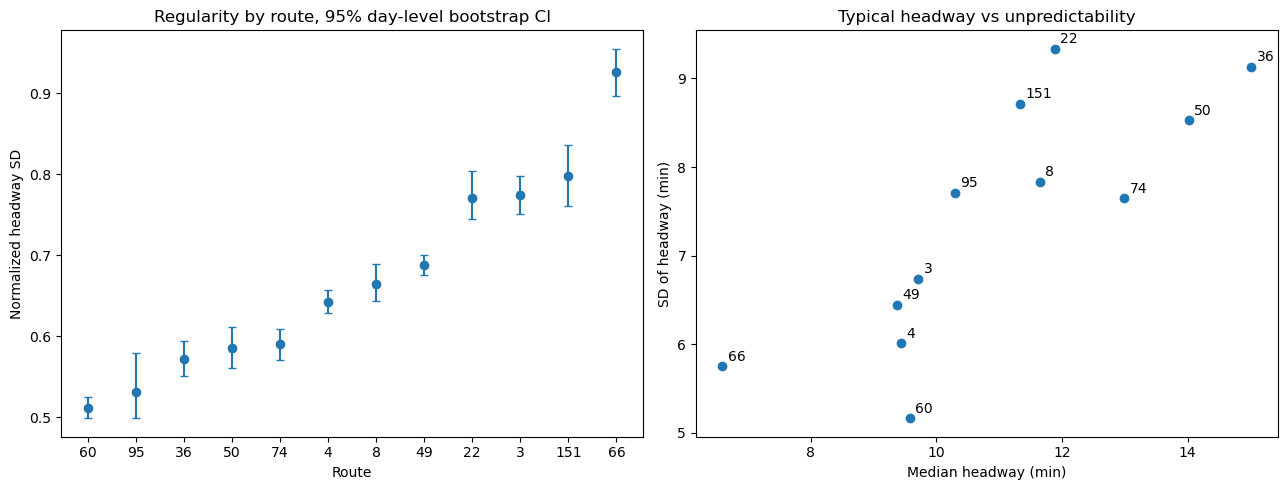

In [49]:
rng = np.random.default_rng(7)
B = 500

def metrics(days, idx):
    h   = np.concatenate([days[i][0] for i in idx])
    hr  = np.concatenate([days[i][1] for i in idx])
    bun = np.concatenate([days[i][2] for i in idx])
    gap = np.concatenate([days[i][3] for i in idx])
    return {"median_h": np.median(h), "sd": h.std(),
            "iqr": np.subtract(*np.percentile(h, [75, 25])),
            "p95": np.percentile(h, 95), "ewt": h.var() / (2 * h.mean()),
            "norm_sd": hr.std(), "p95_ratio": np.percentile(hr, 95),
            "bunched_pct": 100 * bun.mean(), "big_gap_pct": 100 * gap.mean()}

rows = []
for rt, g in hw.groupby("rt"):
    days = [(x["headway_min"].to_numpy(), x["h_ratio_hr"].to_numpy(),
             x["bunched"].to_numpy(float), x["big_gap"].to_numpy(float))
            for _, x in g.groupby("date")]
    est = metrics(days, range(len(days)))
    boots = pd.DataFrame([metrics(days, rng.integers(0, len(days), len(days)))
                          for _ in range(B)])
    row = {"rt": rt, "n": sum(len(d[0]) for d in days)}
    for k, v in est.items():
        row[k] = v
        row[k + "_lo"] = boots[k].quantile(.025)
        row[k + "_hi"] = boots[k].quantile(.975)
    rows.append(row)
res = pd.DataFrame(rows).set_index("rt").sort_values("norm_sd")

def fmt(k, d=2):
    return res.apply(lambda r: f"{r[k]:.{d}f} [{r[k+'_lo']:.{d}f}, {r[k+'_hi']:.{d}f}]", axis=1)

print(pd.DataFrame({"n": res["n"], "median_h": res["median_h"].round(1),
                    "sd_min": fmt("sd", 1), "ewt_min": fmt("ewt", 1),
                    "norm_sd": fmt("norm_sd"), "p95_ratio": fmt("p95_ratio"),
                    "bunched_%": fmt("bunched_pct", 1),
                    "big_gap_%": fmt("big_gap_pct", 1)}).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(res))
ax[0].errorbar(x, res["norm_sd"],
               yerr=[res["norm_sd"] - res["norm_sd_lo"], res["norm_sd_hi"] - res["norm_sd"]],
               fmt="o", capsize=3)
ax[0].set_xticks(x); ax[0].set_xticklabels(res.index)
ax[0].set_xlabel("Route"); ax[0].set_ylabel("Normalized headway SD")
ax[0].set_title("Regularity by route, 95% day-level bootstrap CI")
ax[1].scatter(res["median_h"], res["sd"])
for r, row in res.iterrows():
    ax[1].annotate(r, (row["median_h"], row["sd"]), textcoords="offset points", xytext=(4, 4))
ax[1].set_xlabel("Median headway (min)"); ax[1].set_ylabel("SD of headway (min)")
ax[1].set_title("Typical headway vs unpredictability")
plt.tight_layout(); plt.show()

### Cell 45: which factors predict a bad headway? (Investigation 7)
No schedule exists, so "late" is redefined in two ways: a **big gap** (more than 2x the usual headway) and a **long wait** (more than 5 minutes above the usual). The cell:
1. Builds a headway-level table `dl` with route, period, weekend, speed deviation (`speed_dm`) and weather.
2. Computes a route table with Wilson CIs for proportions and a chi-square test.
3. Fits **logistic regressions** with Route 60 as the baseline and standard errors clustered by date. Odds ratios above 1 mean higher odds of a bad headway.

**Result (big gap):** odds are 3.7x higher on Route 66, 3.1x on Route 151 and 2.8x on Route 22 than on Route 60. The PM peak has 2.8x the odds of the AM peak. Each extra mph above normal speed goes with 31% lower odds (OR 0.69). Rain has no clear effect.

**Cautions:**
- McFadden R-squared is only 0.04 (0.01 for the long-wait model), so most bad headways cannot be predicted from these variables.
- The chi-square p-values and Wilson intervals treat rows as independent, which they are not, so use the date-clustered logistic results instead.
- The 5-minute outcome ranks routes differently because 5 minutes is a much bigger deviation on a 6.6-minute headway than on a 15-minute one. Use the relative (big-gap) outcome to compare routes.

In [50]:
from statsmodels.stats.proportion import proportion_confint

hw["rt"] = hw["rt"].astype(str)
hw["time_period"] = hw["time_period"].astype(str)
hw["date"] = pd.to_datetime(hw["date"])
hw["weekend"] = (hw["day_type"] == "weekend").astype(int)
hw["med_p"] = hw.groupby(["pid", "day_type", "time_period"])["headway_min"].transform("median")
hw["long5"] = ((hw["headway_min"] - hw["med_p"]) > 5).astype(int)
hw["big_gap_i"] = hw["big_gap"].astype(int)

spd2 = spd[["rt", "date", "time_period", "speed"]].dropna().copy()
spd2["time_period"] = spd2["time_period"].astype(str)
spd2["date"] = pd.to_datetime(spd2["date"])
spd2["speed_dm"] = spd2["speed"] - spd2.groupby(["rt", "time_period"])["speed"].transform("mean")
dl = (hw.merge(spd2[["rt", "date", "time_period", "speed_dm"]], on=["rt", "date", "time_period"])
        .merge(wx[["date", "rain", "temp_c"]], on="date"))
print(dl.shape)

# Route table with Wilson CIs and chi-square
for y in ["big_gap_i", "long5"]:
    tab = dl.groupby("rt")[y].agg(n="size", k="sum")
    lo, hi = proportion_confint(tab["k"], tab["n"], method="wilson")
    tab["rate_%"] = (100 * tab["k"] / tab["n"]).round(1)
    tab["lo_%"], tab["hi_%"] = (100 * lo).round(1), (100 * hi).round(1)
    chi2, p, _, _ = stats.chi2_contingency(np.column_stack([tab["k"], tab["n"] - tab["k"]]))
    print(f"\n{y}: chi-square = {chi2:.0f}, p = {p:.2g} (indicative only, rows not independent)")
    print(tab[["n", "rate_%", "lo_%", "hi_%"]].sort_values("rate_%", ascending=False).to_string())

# Logistic regression, SEs clustered by date
for y in ["big_gap_i", "long5"]:
    f = (f"{y} ~ C(rt, Treatment('60')) + C(time_period, Treatment('AM peak (5-9)'))"
         " + weekend + speed_dm + rain + temp_c")
    m = smf.logit(f, dl).fit(disp=0, cov_type="cluster",
                             cov_kwds={"groups": dl["date"].factorize()[0]})
    ci = np.exp(m.conf_int())
    t = pd.DataFrame({"OR": np.exp(m.params), "lo": ci[0], "hi": ci[1], "p": m.pvalues}).round(3)
    print(f"\n=== Logistic regression: {y} (McFadden R² = {m.prsquared:.3f}) ===")
    print(t[t.index.str.contains(r"C\(rt")].sort_values("OR", ascending=False).to_string())
    print(t[t.index.str.contains("time_period")].to_string())
    print(t.loc[["weekend", "speed_dm", "rain", "temp_c"]].to_string())

(185851, 18)

big_gap_i: chi-square = 1999, p = 0 (indicative only, rows not independent)
         n  rate_%  lo_%  hi_%
rt                            
66   24573    13.9  13.4  14.3
151  14606    11.7  11.2  12.2
22   13296    10.8  10.3  11.4
3    16986     9.1   8.7   9.5
49   18959     8.8   8.4   9.2
8    14237     7.4   7.0   7.8
4    17995     7.2   6.8   7.6
74   13538     6.7   6.3   7.1
95   10112     6.4   5.9   6.9
36   11636     6.1   5.7   6.6
50   11810     6.1   5.6   6.5
60   18103     4.1   3.9   4.4

long5: chi-square = 1425, p = 4e-299 (indicative only, rows not independent)
         n  rate_%  lo_%  hi_%
rt                            
22   13296    27.0  26.3  27.8
151  14606    26.8  26.1  27.6
36   11636    26.1  25.3  26.9
8    14237    23.2  22.5  23.9
50   11810    23.1  22.3  23.9
74   13538    22.0  21.3  22.7
3    16986    21.3  20.7  21.9
49   18959    21.3  20.7  21.9
4    17995    20.1  19.6  20.7
66   24573    18.4  18.0  18.9
95   10112    17.2  16.5  

## Part I. Final route comparison and heatmap
### Cell 46: Investigation 2 on the final data
Compares routes on the three-month, 12-route data, treating each **date x time-period** as a block, so routes are compared under the same daily conditions:
1. Route effect after controlling for block, with partial eta-squared.
2. A **Friedman test** across routes, with **Kendall's W** as the effect size.
3. Pairwise paired Wilcoxon tests across blocks, with Holm correction, and a list of pairs that cannot be told apart.

**Result:** route effect F = 164, partial eta-squared = 0.32 (a large effect). Friedman chi-square = 1214, Kendall's W = 0.34. 60 of 66 route pairs differ. The pairs not separable are 151 and 22, 3 and 49, 22 and 49, 50 and 74, 36 and 60, and 4 and 8. Mean regularity runs from Route 95 (0.48) and Route 60 (0.50) at the best end to 151 (0.74) and 66 (0.83) at the worst.

In [51]:
rdp2["block"] = rdp2["date"].astype(str) + "|" + rdp2["time_period"]
y = "ratio_sd_hr"

# 1) Does route matter once each date-and-period is controlled for?
m_blk  = smf.ols(f"{y} ~ C(block)", rdp2).fit()
m_full = smf.ols(f"{y} ~ C(block) + C(rt)", rdp2).fit()
cmp_ = anova_lm(m_blk, m_full)
ss_rt = cmp_.loc[1, "ss_diff"]
print(f"Route effect given date x period: F = {cmp_.loc[1, 'F']:.1f}, p = {cmp_.loc[1, 'Pr(>F)']:.2g}, "
      f"partial eta² = {ss_rt / (ss_rt + m_full.ssr):.2f}")

# 2) Friedman test across routes, blocks = date x period
piv = rdp2.pivot_table(index="block", columns="rt", values=y)
full = piv.dropna()
fr = stats.friedmanchisquare(*[full[c] for c in full.columns])
W = fr.statistic / (len(full) * (full.shape[1] - 1))
print(f"Friedman: chi2 = {fr.statistic:.0f}, p = {fr.pvalue:.2g}, Kendall's W = {W:.2f} "
      f"({len(full)} complete blocks of {len(piv)})")

# 3) Pairwise paired Wilcoxon across blocks, Holm-adjusted
rows = []
for a, b in combinations(piv.columns, 2):
    d = (piv[a] - piv[b]).dropna()
    rows.append({"A": a, "B": b, "n_blocks": len(d), "mean_diff": d.mean(),
                 "p": stats.wilcoxon(d).pvalue})
ph = pd.DataFrame(rows)
ph["p_holm"] = multipletests(ph["p"], method="holm")[1]
print(f"\n{(ph['p_holm'] < 0.05).sum()} of {len(ph)} route pairs differ (Holm-adjusted)")
print("\nPairs we cannot tell apart:")
print(ph[ph["p_holm"] >= 0.05].sort_values("p_holm")[["A", "B", "mean_diff", "p_holm"]]
        .round(3).to_string(index=False))

print("\nMean regularity by route:")
print(rdp2.groupby("rt")[y].mean().round(3).sort_values().to_string())

Route effect given date x period: F = 163.8, p = 1.7e-311, partial eta² = 0.32
Friedman: chi2 = 1214, p = 1.9e-253, Kendall's W = 0.34 (321 complete blocks of 364)

60 of 66 route pairs differ (Holm-adjusted)

Pairs we cannot tell apart:
  A  B  mean_diff  p_holm
151 22      0.036   0.051
  3 49     -0.010   0.073
 22 49      0.027   0.148
 50 74     -0.016   0.322
 36 60      0.019   0.442
  4  8     -0.012   0.442

Mean regularity by route:
rt
95     0.480
60     0.498
36     0.517
50     0.545
74     0.562
4      0.611
8      0.615
3      0.662
49     0.671
22     0.691
151    0.736
66     0.834


### Cell 47: big-gap heatmap
Computes the share of headways over 2x the usual for each route and period, sorted by PM-peak rate, with a `PM_minus_AM` column and a red heatmap with the percentages printed in each square.

**Result:** the problems are concentrated in the **PM peak** on Routes 66 (22.5%), 3 (18.3%), 151 (17.1%), 22 (15.9%) and 8 (13.6%). Route 66 is bad in every period, Route 3 jumps from 3.4% in the morning to 18.3% in the PM peak, and Routes 60 and 95 stay low and stable. Route 95 is the exception, with its worst period in the morning.

time_period  AM peak (5-9)  Midday (9-15)  PM peak (15-19)  Evening (19-22)  PM_minus_AM
rt                                                                                      
66                    10.8           10.3             22.5             10.8         11.7
3                      3.4            5.1             18.3              8.4         14.9
151                    5.5           11.4             17.1             10.9         11.6
22                     6.4            9.9             15.9              9.7          9.5
8                      2.4            6.3             13.6              8.4         11.2
50                     2.9            4.7             11.3              5.1          8.4
49                     4.9            9.7             10.3              9.2          5.4
74                     8.2            3.8             10.2              5.9          2.0
36                     2.9            6.3              9.7              3.9          6.8
4                    

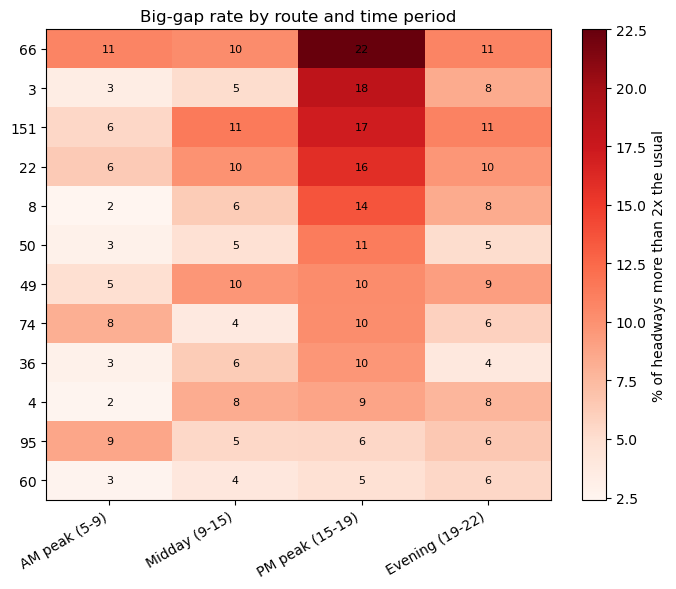

In [52]:
heat = (dl.groupby(["rt", "time_period"])["big_gap_i"].mean().unstack() * 100).round(1)
heat = heat[["AM peak (5-9)", "Midday (9-15)", "PM peak (15-19)", "Evening (19-22)"]]
heat["PM_minus_AM"] = (heat["PM peak (15-19)"] - heat["AM peak (5-9)"]).round(1)
print(heat.sort_values("PM peak (15-19)", ascending=False).to_string())

fig, ax = plt.subplots(figsize=(7, 6))
h = heat.drop(columns="PM_minus_AM").sort_values("PM peak (15-19)", ascending=False)
im = ax.imshow(h.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns, rotation=30, ha="right")
ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        ax.text(j, i, f"{h.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="% of headways more than 2x the usual")
ax.set_title("Big-gap rate by route and time period")
plt.tight_layout(); plt.show()

### Cell 48: empty cell
This cell is empty and can be deleted.

---
# Findings

**Scope.** 12 high-frequency CTA routes (3, 4, 8, 22, 36, 49, 50, 60, 66, 74, 95, 151), 24 route patterns, April to June 2026 (91 days, 26 of them weekend days), 185,851 cleaned headways measured at one mid-route reference stop per pattern. Routes 79, 9, 77, 12, 20 and 55 were excluded because buses were missing from the data, and Routes 53 and 63 for too little service.

**Measurement.** The data has estimated arrival times but no schedule, so *delay* is replaced by **headway** (minutes between consecutive buses), normalized by each pattern's usual headway for its day type and hour. *Late* is replaced by **big gap** (more than 2x the usual) and **bunched** (under 25% of the usual).

## Investigation 1 and 2: Are some routes less reliable?
**Yes, by a large and consistent margin.**
- With each date and time period held fixed, route explains about a third of the variation in regularity (F = 164, partial eta-squared = 0.32). A rank-based test agrees (Friedman chi-square = 1,214, Kendall's W = 0.34), and **60 of 66 route pairs differ** after Holm correction.
- Mean regularity (normalized SD) runs from **Route 95 (0.48) and Route 60 (0.50)** at the best end to **Route 151 (0.74) and Route 66 (0.83)** at the worst.
- Bands (normalized SD from the bootstrap table): most regular 60 and 95 (0.51 to 0.53); good 36, 50 and 74 (0.57 to 0.59); middling 4, 8 and 49 (0.64 to 0.69); poor 22, 3 and 151 (0.77 to 0.80); worst **66 (0.93)**. Pairs that cannot be told apart: 151 and 22, 3 and 49, 22 and 49, 50 and 74, 36 and 60, 4 and 8.
- The ranking was stable across one-month and three-month data, and with or without the questionable routes.
- **Average delay (Question 2) cannot be measured** without scheduled times. The closest proxy, expected excess wait, is highest on Routes 22 (3.4 min) and 151 (3.1 min) and lowest on Route 60 (1.3 min).

## Investigation 6: Unpredictability beyond the average
- Routes with the same typical frequency differ sharply. Routes 60, 4, 49 and 3 all run about every 9.5 minutes, but their headway SDs are 5.2, 6.0, 6.4 and 6.7 minutes. **Route 3 imposes about 70% more excess wait than Route 60** (2.2 vs 1.3 minutes).
- **Route 66** has the highest bunching (14.9%) and the most big gaps (13.9%). Routes 151, 22 and 3 are also elevated on both (12.5% to 13.9% bunched; 9.1% to 11.7% big gaps), roughly double Route 60 (6.1% and 4.1%). Route 95 has the lowest bunching (4.5%) but a higher gap rate (6.4%).

## Investigation 3: Time of day
- **The weekday PM peak (3 to 7 pm) is the weak spot.** Compared with the AM peak, headway variability is higher by **0.254** at the PM peak (95% CI 0.232 to 0.275), 0.083 at midday and 0.079 in the evening. The result holds when headways are normalized by hour, so it is not a schedule ramp-up artifact.
- The odds of a big gap are **2.8 times higher** at the PM peak than in the morning.
- The effect is uneven across routes (route x period interaction, F = 16.3, p < 0.0001, April data). Big-gap rate in the PM peak: **Route 66 22.5%**, Route 3 18.3% (up from 3.4% in the morning), Route 151 17.1%, Route 22 15.9%, Route 8 13.6%. **Route 60 stays under 6% all day.** Route 95 is the exception, worst in the morning (8.7%).

## Investigation 4: Weekday vs weekend
- **Weekends are not less reliable.** Overall, weekends are slightly more regular (-0.035, 95% CI -0.061 to -0.009), but this comes almost entirely from the **morning**: weekend mornings are more regular on **all 12 routes** (difference 0.176, Wilcoxon p = 0.0005, about 0.002 after correcting for four period tests).
- Midday, afternoon and evening show no consistent weekday/weekend difference.
- This is a **correction of an earlier result.** In April alone the weekend advantage looked more than twice as large (about 0.08), and it shrank with more data. Only 26 weekend days are in the sample.

## Investigation 5: Congestion proxy and weather
- Using bus speed relative to a route's own usual speed as a congestion proxy, each extra mph goes with **-0.091** headway variability (95% CI -0.113 to -0.069), after adjusting for route, period, weekend and weather. On slow, medium and fast days (April) mean variability is 0.659, 0.599 and 0.537.
- **Rain has no detectable effect** (at least 5 mm, 20 of 91 days): -0.003 (95% CI -0.029 to +0.022).
- Practical size is small: a typical speed swing is about 0.5 mph, which moves variability by about 0.05, against 0.25 for the PM-peak effect. Speed measures how fast buses move, not traffic itself, and the link may run both ways because bunched buses slow each other down.

## Investigation 7: What predicts a big gap?
- Odds of a big gap relative to Route 60: **Route 66 3.7x** (CI 3.4 to 4.1), **Route 151 3.1x**, **Route 22 2.8x**, Routes 3 and 49 about 2.3x, Route 8 1.9x, Route 4 1.8x, Routes 95 and 74 about 1.6x, Route 36 1.5x, Route 50 1.5x.
- Time of day: PM peak 2.8x, evening 1.6x, midday 1.5x (vs AM peak). Speed: 31% lower odds per extra mph (OR 0.69). Weekend 1.2x. Rain: no clear effect (OR 0.96).
- **The model explains very little** (McFadden R-squared 0.038). Route and time of day are consistent drivers, but most individual bad headways cannot be predicted from the available variables.
- A fixed "more than 5 minutes above usual" outcome ranks routes differently (Routes 22, 151 and 36 look worst, Route 66 nearly fine, R-squared 0.011), because 5 minutes is a far bigger deviation on a 6.6-minute headway than on a 15-minute one. The relative definition is the fairer comparison across routes.

## Limitations
- Arrival times are **interpolated estimates**; there is no true schedule delay, and headway regularity is not the same as punctuality.
- **Only 12 of 20 shortlisted routes** are analyzed, all frequent main-line routes. Exclusions for missing data could flatter the network if missing data coincides with real service problems.
- Three months, with about **91 effectively independent days** (all routes share each day's conditions), so intervals are somewhat optimistic. Weekend results rest on 26 days.
- Thresholds (2x usual, 25% of usual) are conventions. Speed and weather are weak proxies, and weather is a daily total.
- All results are **observational**: associations, not proven causes. Many tests were run; pairwise results use Holm correction.

---
# Conclusion

Bus reliability on the analyzed CTA routes is neither uniform nor random. Differences **between routes** are large and persistent, and differences **by time of day** are clear. Both are far stronger than anything attributable to weekday versus weekend or to rain.

The **weekday afternoon peak** is where bus spacing breaks down most, and it does so unevenly: **Route 66** is poor throughout the day, **Routes 3, 151, 22 and 8** deteriorate sharply in the afternoon, and **Routes 60 and 95** show that steady service is achievable on this network. Weekends are not worse than weekdays; the one clear difference is that weekday mornings are less regular than weekend mornings.

**Recommendations** that follow from the evidence:
1. **Target the weekday PM peak** with spacing-based control (dispatch and holding by headway, field supervisors) on Routes 66, 3, 151, 22 and 8.
2. **Prioritize Route 66**, which has the highest bunching and gap rates in every period.
3. **Look at afternoon capacity on Routes 3, 151, 22 and 8**: spare vehicles, layover recovery time, missed trips and operator availability.
4. **Use Routes 60 and 95 as benchmarks** and compare their scheduling and dispatch with the worst routes.
5. **Investigate why weekend mornings are more regular**, since that may point to a fix for weekday mornings.
6. **Pilot and evaluate** any change against a comparable control route using the same headway metrics.
7. **Improve the data**: official schedule-adherence data, hourly weather, traffic speeds and passenger counts, and coverage for the six excluded routes, so delay and congestion can be analyzed directly.

These findings show **where** service is weakest, not why. A Word report with charts is available alongside this notebook (`CTA_Bus_Reliability_Report.docx`).
